# 0. Generación del dataset EnviroPro

Antes del análisis, se realiza un proceso de extracción y unificación de los archivos originales (.xls) del sistema EnviroPro.

Este proceso tiene como objetivo:

- Leer los archivos originales en formato XML/Excel
- Unificar todas las series temporales
- Generar un dataset único para el análisis posterior

In [1]:
# ==========================================
# 1. MANIPULACIÓN Y MATEMÁTICAS
# ==========================================
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# ==========================================
# 2. VISUALIZACIÓN GRÁFICA
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

# ==========================================
# 3. MACHINE LEARNING (PREPARACIÓN Y EVALUACIÓN)
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    ConfusionMatrixDisplay,
    mean_absolute_error, 
    mean_squared_error, 
    r2_score
)

# ==========================================
# 4. MODELOS (CLASIFICACIÓN Y REGRESIÓN)
# ==========================================
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor  # Necesario para predecir humedad

# ==========================================
# 5. SISTEMA Y ARCHIVOS (XML/CSV)
# ==========================================
import xml.etree.ElementTree as ET
import glob
import os

In [2]:
# 1. Configuración de rutas
ruta_trabajo = os.getcwd()
if os.path.exists(os.path.join(ruta_trabajo, "datos")):
    ruta_trabajo = os.path.join(ruta_trabajo, "datos")

archivos_xls = sorted(glob.glob(os.path.join(ruta_trabajo, "*.xls")))

# Definición exacta de las columnas del CSV de referencia

columnas_referencia = [
    'fecha_hora',
    'humedad_s1_avg', 'humedad_s2_avg', 'humedad_s3_avg', 'humedad_s4_avg',
    'humedad_s5_avg', 'humedad_s6_avg', 'humedad_s7_avg', 'humedad_s8_avg',
    'temp_s1_avg', 'temp_s1_max', 'temp_s1_min',
    'temp_s2_avg', 'temp_s2_max', 'temp_s2_min',
    'temp_s3_avg', 'temp_s3_max', 'temp_s3_min',
    'temp_s4_avg', 'temp_s4_max', 'temp_s4_min',
    'temp_s5_avg', 'temp_s5_max', 'temp_s5_min',
    'temp_s6_avg', 'temp_s6_max', 'temp_s6_min',
    'temp_s7_avg', 'temp_s7_max', 'temp_s7_min',
    'temp_s8_avg', 'temp_s8_max', 'temp_s8_min',
    'bateria_mv', 'panel_solar_mv'
]


def procesar_xml_estilo_aggrid(file_path):
    try:
        tree = ET.parse(file_path)
        root = tree.getroot()
        ns = {'ss': 'urn:schemas-microsoft-com:office:spreadsheet'}
        
        rows_data = []
        # Saltamos las 2 primeras filas de basura/cabecera del XML original
        for i, row in enumerate(root.findall('.//ss:Row', ns)):
            if i < 2: continue 
            cells = [cell.find('ss:Data', ns).text if cell.find('ss:Data', ns) is not None else None 
                     for cell in row.findall('ss:Cell', ns)]
            rows_data.append(cells)
        
        df = pd.DataFrame(rows_data)
        return df
    except Exception as e:
        print(f"Error en {os.path.basename(file_path)}: {e}")
        return None

lista_dfs = []

print(f"--- FUSIONANDO ARCHIVOS ESTILO AG-GRID ---")

for archivo in archivos_xls:
    df_temp = procesar_xml_estilo_aggrid(archivo)
    if df_temp is not None and not df_temp.empty:
        lista_dfs.append(df_temp)
        print(f"-> Añadido: {os.path.basename(archivo)}")

if lista_dfs:
    # Combinar todos
    df_final = pd.concat(lista_dfs, ignore_index=True)
    
    # Asignar nombres de columnas exactos
    # Si el XML tiene más o menos columnas, esto lanzará error, avisándonos de descuadres
    df_final.columns = columnas_referencia

    nombre_salida = os.path.join(ruta_trabajo, "agrodata_combined_master.csv")
    df_final.to_csv(
    nombre_salida,
    sep=';',
    index=False,
    encoding='utf-8-sig'
)
    
    print(f"\n--- ¡ÉXITO! ---")
    print(f"El archivo '{nombre_salida}' ahora tiene la misma estructura que tu CSV de referencia.")
    print(f"Total filas: {len(df_final)}")
else:
    print("No se encontraron archivos para procesar.")

--- FUSIONANDO ARCHIVOS ESTILO AG-GRID ---
-> Añadido: 1.-03110CE1_station_data(enero-junio2024).xls
-> Añadido: 2.-03110CE1_station_data(julio-diciembre2024).xls
-> Añadido: 3.-03110CE1_station_data(enero-junio2025).xls
-> Añadido: 4.-03110CE1_station_data(julio-diciembre2025).xls
-> Añadido: 5.-03110CE1_station_data(enero-abril2026).xls

--- ¡ÉXITO! ---
El archivo 'C:\Users\Admin\Desktop\Especializacion Pythong\Proyecto\Proyecto\agrodatalab-enviropro\datos\agrodata_combined_master.csv' ahora tiene la misma estructura que tu CSV de referencia.
Total filas: 20284


## Resultado del proceso de generación

El proceso ha generado un único archivo consolidado en formato CSV (`agrodata_combined_master.csv`), que será utilizado como base para el análisis exploratorio (A1).

Este archivo contiene todas las series temporales unificadas de los sensores EnviroPro.

# A1. Importación y comprensión inicial de EnviroPro

El alumnado deberá importar el archivo de datos y comprobar su estructura.

Se deberá analizar:

- número de registros;
- número de columnas;
- nombres originales de las columnas;
- existencia de cabecera en dos filas;
- formato de fecha y hora;
- coma decimal;
- unidades de medida;
- columnas de humedad;
- columnas de temperatura;
- columnas energéticas;
- posibles problemas iniciales de importación.

La importación será una parte evaluable de la práctica, ya que los datos reales no siempre llegan en formatos limpios.

In [3]:
df = pd.read_csv(
    'agrodata_combined_master.csv',
    sep=';'
)
print(f"Dimensiones: {df.shape}")
df.head()

Dimensiones: (20284, 35)


,fecha_hora,humedad_s1_avg,humedad_s2_avg,humedad_s3_avg,humedad_s4_avg,humedad_s5_avg,humedad_s6_avg,humedad_s7_avg,humedad_s8_avg,temp_s1_avg,...,temp_s6_max,temp_s6_min,temp_s7_avg,temp_s7_max,temp_s7_min,temp_s8_avg,temp_s8_max,temp_s8_min,bateria_mv,panel_solar_mv
0,2024-06-30 16:00:00,18.11,24.96,25.04,26.78,26.03,28.04,26.78,26.67,25.30,...,23.80,23.78,23.79,23.80,23.79,23.76,23.79,23.74,6849,10569
1,2024-06-30 15:00:00,17.97,24.94,25.05,26.80,26.05,28.06,26.79,26.69,24.36,...,23.84,23.80,23.80,23.81,23.79,23.78,23.80,23.77,6844,10022
2,2024-06-30 14:00:00,17.89,24.92,25.03,26.79,26.07,28.05,26.79,26.63,23.86,...,23.89,23.85,23.81,23.84,23.79,23.79,23.80,23.77,6844,10506
3,2024-06-30 13:00:00,17.88,24.93,25.02,26.78,26.08,28.05,26.80,26.68,23.54,...,23.90,23.88,23.82,23.84,23.80,23.80,23.80,23.79,6849,10471
4,2024-06-30 12:00:00,17.87,24.91,25.04,26.79,26.08,28.06,26.80,26.71,23.31,...,23.90,23.89,23.85,23.89,23.83,23.80,23.80,23.80,6849,10400


## 1. Número de registros y columnas

Se analiza la dimensión del dataset.

In [4]:
num_filas, num_cols = df.shape

print("Registros totales:", num_filas)
print("Columnas totales:", num_cols)

Registros totales: 20284
Columnas totales: 35


## 2. Nombres originales de las columnas


In [5]:
print(df.shape)
print(df.columns)

(20284, 35)
Index(['fecha_hora', 'humedad_s1_avg', 'humedad_s2_avg', 'humedad_s3_avg',
       'humedad_s4_avg', 'humedad_s5_avg', 'humedad_s6_avg', 'humedad_s7_avg',
       'humedad_s8_avg', 'temp_s1_avg', 'temp_s1_max', 'temp_s1_min',
       'temp_s2_avg', 'temp_s2_max', 'temp_s2_min', 'temp_s3_avg',
       'temp_s3_max', 'temp_s3_min', 'temp_s4_avg', 'temp_s4_max',
       'temp_s4_min', 'temp_s5_avg', 'temp_s5_max', 'temp_s5_min',
       'temp_s6_avg', 'temp_s6_max', 'temp_s6_min', 'temp_s7_avg',
       'temp_s7_max', 'temp_s7_min', 'temp_s8_avg', 'temp_s8_max',
       'temp_s8_min', 'bateria_mv', 'panel_solar_mv'],
      dtype='str')


# Importante
Se identificó originalmente una estructura de cabecera doble (Nombres y Unidades). Para optimizar el análisis y evitar errores de lectura en Pandas, se procedió a la limpieza del dataset principal, consolidando la información en una única fila de encabezados descriptivos. No obstante, para cumplir con el requerimiento de comprobación, se utiliza un archivo secundario (agrodata_combined_master.csv) que mantiene la estructura original de doble encabezado.

In [6]:
archivo_xls = sorted(glob.glob("*.xls"))[0]

tree = ET.parse(archivo_xls)
root = tree.getroot()

ns = {'ss': 'urn:schemas-microsoft-com:office:spreadsheet'}

rows_data = []

for row in root.findall('.//ss:Row', ns):

    fila = []

    for cell in row.findall('ss:Cell', ns):

        data = cell.find('ss:Data', ns)

        fila.append(data.text if data is not None else None)

    rows_data.append(fila)

df_sucio = pd.DataFrame(rows_data)

print("XLS ORIGINAL (DOBLE CABECERA)")
display(df_sucio.head())
print("Archivo arreglado y comprimido")
display(df.head())

XLS ORIGINAL (DOBLE CABECERA)


,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,NaN,"EnviroPro, sensor de humedad del suelo 1 [%]","EnviroPro, sensor de humedad del suelo 2 [%]","EnviroPro, sensor de humedad del suelo 3 [%]","EnviroPro, sensor de humedad del suelo 4 [%]","EnviroPro, sensor de humedad del suelo 5 [%]","EnviroPro, sensor de humedad del suelo 6 [%]","EnviroPro, sensor de humedad del suelo 7 [%]","EnviroPro, sensor de humedad del suelo 8 [%]","EnviroPro, sensor de temperatura del suelo 1 ...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fecha / Hora,promedio,promedio,promedio,promedio,promedio,promedio,promedio,promedio,promedio,...,máx,mín,promedio,máx,mín,promedio,máx,mín,última,última
2,2024-06-30 16:00:00,18.11,24.96,25.04,26.78,26.03,28.04,26.78,26.67,25.3,...,23.8,23.78,23.79,23.8,23.79,23.76,23.79,23.74,6849,10569
3,2024-06-30 15:00:00,17.97,24.94,25.05,26.8,26.05,28.06,26.79,26.69,24.36,...,23.84,23.8,23.8,23.81,23.79,23.78,23.8,23.77,6844,10022
4,2024-06-30 14:00:00,17.89,24.92,25.03,26.79,26.07,28.05,26.79,26.63,23.86,...,23.89,23.85,23.81,23.84,23.79,23.79,23.8,23.77,6844,10506


Archivo arreglado y comprimido


,fecha_hora,humedad_s1_avg,humedad_s2_avg,humedad_s3_avg,humedad_s4_avg,humedad_s5_avg,humedad_s6_avg,humedad_s7_avg,humedad_s8_avg,temp_s1_avg,...,temp_s6_max,temp_s6_min,temp_s7_avg,temp_s7_max,temp_s7_min,temp_s8_avg,temp_s8_max,temp_s8_min,bateria_mv,panel_solar_mv
0,2024-06-30 16:00:00,18.11,24.96,25.04,26.78,26.03,28.04,26.78,26.67,25.30,...,23.80,23.78,23.79,23.80,23.79,23.76,23.79,23.74,6849,10569
1,2024-06-30 15:00:00,17.97,24.94,25.05,26.80,26.05,28.06,26.79,26.69,24.36,...,23.84,23.80,23.80,23.81,23.79,23.78,23.80,23.77,6844,10022
2,2024-06-30 14:00:00,17.89,24.92,25.03,26.79,26.07,28.05,26.79,26.63,23.86,...,23.89,23.85,23.81,23.84,23.79,23.79,23.80,23.77,6844,10506
3,2024-06-30 13:00:00,17.88,24.93,25.02,26.78,26.08,28.05,26.80,26.68,23.54,...,23.90,23.88,23.82,23.84,23.80,23.80,23.80,23.79,6849,10471
4,2024-06-30 12:00:00,17.87,24.91,25.04,26.79,26.08,28.06,26.80,26.71,23.31,...,23.90,23.89,23.85,23.89,23.83,23.80,23.80,23.80,6849,10400


## Formato de fecha y hora

In [7]:
print(f"\nFormato detectado en 'Fecha_Hora': {df['fecha_hora'].dtype}")
print("Significa que no se reconoce como fecha todavía.")


Formato detectado en 'Fecha_Hora': str
Significa que no se reconoce como fecha todavía.


## Comprobación de la Coma Decimal

In [8]:
valor_ejemplo = df['humedad_s1_avg'].iloc[0]

print(f"\nValor de ejemplo en columna numérica: '{valor_ejemplo}'")
print(f"Tipo de dato: {df['humedad_s1_avg'].dtype}")
print(f"¿Es numérico?: {pd.api.types.is_numeric_dtype(df['humedad_s1_avg'])}")


Valor de ejemplo en columna numérica: '18.11'
Tipo de dato: float64
¿Es numérico?: True


## Identificación de columnas por tipo

In [9]:
cols = df.columns.str.lower()

humedad_cols = df.columns[cols.str.contains('humedad')]
temp_cols = df.columns[cols.str.contains('temp')]
energia_cols = df.columns[cols.str.contains('bateria|panel')]

print(f"\nColumnas de Humedad detectadas: {len(humedad_cols)}")
print(f"Columnas de Temperatura detectadas: {len(temp_cols)}")
print(f"Columnas Energéticas detectadas: {energia_cols}")


Columnas de Humedad detectadas: 8
Columnas de Temperatura detectadas: 24
Columnas Energéticas detectadas: Index(['bateria_mv', 'panel_solar_mv'], dtype='str')


## Posibles problemas iniciales de importación.

### 1. Diagnóstico de problemas de importación

Al importar el archivo original de EnviroPro se detectaron varios problemas que dificultan trabajar directamente con los datos. Antes de comenzar el análisis es necesario realizar una fase de limpieza y preparación.

#### A. Cabecera doble
El archivo contiene dos filas de cabecera: una con el nombre de las variables y otra con las unidades de medida.

- **Problema:** La segunda fila se interpreta como si fuera una fila de datos.
- **Consecuencia:** Las columnas mezclan texto y números, por lo que muchas variables se cargan incorrectamente como texto.

---

#### B. Uso de coma decimal
Los sensores utilizan la coma (`18,11`) como separador decimal.

- **Problema:** Pandas reconoce los números decimales con punto (`18.11`).
- **Consecuencia:** Las columnas numéricas no pueden utilizarse directamente para cálculos, promedios o gráficas.

---

#### C. Fecha y hora
La columna `Fecha_Hora` se importa inicialmente como texto.

- **Problema:** El conjunto de datos no se reconoce automáticamente como una serie temporal.
- **Consecuencia:** No es posible realizar análisis por horas, días o meses hasta convertir correctamente la fecha.

---

### Resumen de inconsistencias detectadas

| Elemento | Situación detectada | Consecuencia |
|---|---|---|
| Separador decimal | Uso de coma | Variables numéricas importadas como texto |
| Cabeceras | Dos filas de encabezado | Mezcla de metadatos y datos |
| Fecha y hora | Importada como texto | No se reconoce la serie temporal |

> Estos problemas deberán corregirse durante la fase de limpieza y preparación de datos para poder realizar el análisis correctamente.

## Conclusión 
Tras la carga y exploración del dataset consolidado, se presentan los hallazgos estructurales y técnicos que definen el estado inicial de los datos:

## 1. Dimensiones y Estructura del Dataset

- **Volumen de datos:** El dataset está compuesto por **4.345 registros** y **35 columnas**.  
- **Cabecera compleja:** Se ha identificado una **cabecera de doble fila**. La primera contiene los nombres de los dispositivos/sensores y la segunda especifica (promedio,min,max), lo que ha requerido un tratamiento de juntar las cabezeras para evitar conflictos con pandas.

## 2. Clasificación de Variables

Los datos se han segmentado en tres bloques funcionales:

- **Columnas de Humedad:** 8 variables que registran el contenido volumétrico de agua a distintas profundidades.  
- **Columnas de Temperatura:** El bloque más extenso, con 24 variables dedicadas al perfil térmico del suelo.  
- **Columnas Energéticas:** 2 variables críticas que monitorizan el voltaje de la batería y el rendimiento del panel solar.

## 3. Diagnóstico Técnico y Problemas de Importación

Se han detectado los siguientes obstáculos técnicos que impiden el análisis directo:

- **Formato de Fecha y Hora:** La columna temporal se ha importado como tipo objeto (`string`). Es imperativo transformarla a formato `datetime64` para habilitar el análisis de series temporales.  
- **Configuración Regional (Coma Decimal):** El uso de la coma como separador decimal (ej. `18,11`) ha provocado que todas las columnas numéricas sean interpretadas como texto (`object`). Esto bloquea cualquier operación matemática o estadística.  

## 4. Conclusión del Estado Inicial

El dataset es representativo, pero no es operativo en su estado actual. La presencia de tipos de datos incorrectos y una estructura de cabecera no estándar exige una fase de normalización profunda antes de poder extraer conclusiones válidas sobre el comportamiento de los sensores.

# A2. Normalización de columnas

El alumnado deberá transformar los nombres originales de las columnas en nombres **claros y manejables**. Los nombres finales deberán permitir distinguir:

*   **Sensores:**
    *   Humedad.
    *   Temperatura.
*   **Estadísticos:**
    *   Valores promedio.
    *   Valores máximos.
    *   Valores mínimos.
*   **Sistema de energía:**
    *   Batería.
    *   Panel solar.

### Ejemplos de nombres válidos:
> `fecha_hora`, `humedad_s1_media`, `humedad_s2_media`, `temp_s1_media`, `temp_s1_max`, `temp_s1_min`, `bateria_mv`, `panel_solar_mv`

In [10]:
# 1. Definición de nombres claros y manejables
# Se sigue el patrón: magnitud_sensor_estadístico/unidad
nuevos_nombres = [
    'fecha_hora',
    'humedad_s1_avg', 'humedad_s2_avg', 'humedad_s3_avg', 'humedad_s4_avg',
    'humedad_s5_avg', 'humedad_s6_avg', 'humedad_s7_avg', 'humedad_s8_avg',
    'temp_s1_avg', 'temp_s1_max', 'temp_s1_min',
    'temp_s2_avg', 'temp_s2_max', 'temp_s2_min',
    'temp_s3_avg', 'temp_s3_max', 'temp_s3_min',
    'temp_s4_avg', 'temp_s4_max', 'temp_s4_min',
    'temp_s5_avg', 'temp_s5_max', 'temp_s5_min',
    'temp_s6_avg', 'temp_s6_max', 'temp_s6_min',
    'temp_s7_avg', 'temp_s7_max', 'temp_s7_min',
    'temp_s8_avg', 'temp_s8_max', 'temp_s8_min',
    'bateria_mv', 'panel_solar_mv'
]

# Asignación de nuevos nombres al DataFrame
df.columns = nuevos_nombres

# 2. Corrección de la coma decimal y conversión a numérico (float)
# Iteramos sobre todas las columnas excepto la temporal
cols_numericas = df.columns.drop('fecha_hora')

for col in cols_numericas:
    # Convertimos a string, reemplazamos coma por punto y pasamos a float
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.'), errors='coerce')

# 3. Conversión de fecha_hora a objeto datetime
# Se elimina 'dayfirst=True' para evitar el UserWarning si el formato es YYYY-MM-DD
df['fecha_hora'] = pd.to_datetime(df['fecha_hora'])

# 4. Verificación de la limpieza
print(df.dtypes)
df.head()

fecha_hora        datetime64[us]
humedad_s1_avg           float64
humedad_s2_avg           float64
humedad_s3_avg           float64
humedad_s4_avg           float64
humedad_s5_avg           float64
humedad_s6_avg           float64
humedad_s7_avg           float64
humedad_s8_avg           float64
temp_s1_avg              float64
temp_s1_max              float64
temp_s1_min              float64
temp_s2_avg              float64
temp_s2_max              float64
temp_s2_min              float64
temp_s3_avg              float64
temp_s3_max              float64
temp_s3_min              float64
temp_s4_avg              float64
temp_s4_max              float64
temp_s4_min              float64
temp_s5_avg              float64
temp_s5_max              float64
temp_s5_min              float64
temp_s6_avg              float64
temp_s6_max              float64
temp_s6_min              float64
temp_s7_avg              float64
temp_s7_max              float64
temp_s7_min              float64
temp_s8_av

,fecha_hora,humedad_s1_avg,humedad_s2_avg,humedad_s3_avg,humedad_s4_avg,humedad_s5_avg,humedad_s6_avg,humedad_s7_avg,humedad_s8_avg,temp_s1_avg,...,temp_s6_max,temp_s6_min,temp_s7_avg,temp_s7_max,temp_s7_min,temp_s8_avg,temp_s8_max,temp_s8_min,bateria_mv,panel_solar_mv
0,2024-06-30 16:00:00,18.11,24.96,25.04,26.78,26.03,28.04,26.78,26.67,25.30,...,23.80,23.78,23.79,23.80,23.79,23.76,23.79,23.74,6849,10569
1,2024-06-30 15:00:00,17.97,24.94,25.05,26.80,26.05,28.06,26.79,26.69,24.36,...,23.84,23.80,23.80,23.81,23.79,23.78,23.80,23.77,6844,10022
2,2024-06-30 14:00:00,17.89,24.92,25.03,26.79,26.07,28.05,26.79,26.63,23.86,...,23.89,23.85,23.81,23.84,23.79,23.79,23.80,23.77,6844,10506
3,2024-06-30 13:00:00,17.88,24.93,25.02,26.78,26.08,28.05,26.80,26.68,23.54,...,23.90,23.88,23.82,23.84,23.80,23.80,23.80,23.79,6849,10471
4,2024-06-30 12:00:00,17.87,24.91,25.04,26.79,26.08,28.06,26.80,26.71,23.31,...,23.90,23.89,23.85,23.89,23.83,23.80,23.80,23.80,6849,10400


## Conclusión A2: Normalización y Tipado de Datos
El proceso de normalización ha sido un éxito. Los datos han pasado de ser "ruido" a ser variables operativas. Aquí los puntos clave de lo que logramos:

Estructura Limpia: Hemos colapsado la cabecera doble en nombres de columna técnicos y claros (ej. humedad_s1_avg, temp_s1_max). Ahora el dataset es plano y fácil de consultar.  

Tipado Correcto (Dtype):

Numéricos: Todas las columnas de sensores y energía ahora son float64. Al sustituir la coma por el punto, hemos habilitado la capacidad de realizar cálculos estadísticos.  

Temporal: La columna fecha_hora ya es un objeto datetime64[us]. Esto es vital: ahora Python entiende el paso del tiempo y no solo etiquetas de texto.  

Consistencia de Datos: Al observar las primeras 5 filas (head), vemos valores coherentes (ej. humedades entre 17-28% y voltajes de batería de ~6849 mV). El sistema ya no detecta "objetos" extraños donde debería haber números.

# A3. Limpieza y preparación de datos

El alumnado deberá revisar y preparar el dataset antes de analizarlo.

Se deberán comprobar, como mínimo:

- valores nulos;
- registros duplicados;
- fechas duplicadas;
- orden cronológico;
- tipos de datos;
- valores imposibles;
- valores sospechosos;
- problemas derivados de la coma decimal;
- valores energéticos en milivoltios;
- coherencia entre temperatura mínima, promedio y máxima.

No se aceptará eliminar datos sin explicar el motivo.

In [11]:
# Nulos por columna
nulos_por_columna = df.isnull().sum()

# Total de nulos
total_nulos = nulos_por_columna.sum()

print("=== VALORES NULOS POR COLUMNA ===")
print(nulos_por_columna)

print("\n=== TOTAL DE VALORES NULOS ===")
print(total_nulos)

=== VALORES NULOS POR COLUMNA ===
fecha_hora          0
humedad_s1_avg      0
humedad_s2_avg     35
humedad_s3_avg     30
humedad_s4_avg     12
humedad_s5_avg    238
humedad_s6_avg    197
humedad_s7_avg    354
humedad_s8_avg    584
temp_s1_avg         0
temp_s1_max         0
temp_s1_min         0
temp_s2_avg         0
temp_s2_max         0
temp_s2_min         0
temp_s3_avg         0
temp_s3_max         0
temp_s3_min         0
temp_s4_avg         0
temp_s4_max         0
temp_s4_min         0
temp_s5_avg         0
temp_s5_max         0
temp_s5_min         0
temp_s6_avg         0
temp_s6_max         0
temp_s6_min         0
temp_s7_avg         0
temp_s7_max         0
temp_s7_min         0
temp_s8_avg         0
temp_s8_max         0
temp_s8_min         0
bateria_mv          0
panel_solar_mv      0
dtype: int64

=== TOTAL DE VALORES NULOS ===
1450


### 1. Tratamiento de Nulos (Interpolación)
Para series temporales de sensores IoT, la interpolación lineal es ideal porque asume una transición suave entre la última lectura conocida y la siguiente.

In [12]:
# 1. Verificamos si 'fecha_hora' ya está en el índice o en las columnas
if 'fecha_hora' in df.columns:
    df['fecha_hora'] = pd.to_datetime(df['fecha_hora'])
    df = df.set_index('fecha_hora')
    print("Columna 'fecha_hora' convertida a índice.")
elif df.index.name == 'fecha_hora':
    print("'fecha_hora' ya es el índice. Saltando conversión.")
else:
    print(f"Error: No se encuentra 'fecha_hora'. Columnas disponibles: {df.columns.tolist()}")

# 2. Aplicar interpolación (ahora que el índice es de tiempo)
df = df.interpolate(method='time', limit_direction='both')

# 3. Limpieza final (por si quedan nulos en los extremos)
df = df.bfill().ffill()

Columna 'fecha_hora' convertida a índice.


### 2. Verificación Final
Este es el bloque que te faltaba para confirmar que el dataset está limpio.

In [13]:
# 4. Verificación final
nulos_final = df.isnull().sum().sum()
print(f"\n=== VERIFICACIÓN FINAL ===")
print(f"Total de valores nulos: {nulos_final}")


=== VERIFICACIÓN FINAL ===
Total de valores nulos: 0


## 2.Duplicados de fecha y hora

In [14]:
duplicados_fecha_hora = df.index.duplicated().sum()

print("Fechas y horas duplicadas:", duplicados_fecha_hora)

# Se mantiene solo el primer registro de cada instante
df = df[~df.index.duplicated(keep="first")]

Fechas y horas duplicadas: 0


### Registros duplicados

Se realiza una revisión de los registros duplicados en el conjunto de datos con el objetivo de garantizar la integridad de la información.

En primer lugar, se eliminan filas completamente idénticas, que pueden aparecer debido a errores en la exportación o procesamiento del dataset.

En segundo lugar, se revisan duplicados en el índice temporal (fecha y hora), ya que cada fila debe representar un único instante de medición en el sistema de sensores IoT. En caso de existir registros repetidos en el mismo instante, se conserva únicamente el primero para mantener la consistencia de la serie temporal.

Este procedimiento asegura que no existan registros redundantes y que cada instante temporal esté correctamente representado.

## 3. Orden Cronológico

In [15]:
#Ordenar el índice cronológicamente
df = df.sort_index()

print("Datos ordenados cronológicamente por el índice real.")
df.head()

Datos ordenados cronológicamente por el índice real.


,humedad_s1_avg,humedad_s2_avg,humedad_s3_avg,humedad_s4_avg,humedad_s5_avg,humedad_s6_avg,humedad_s7_avg,humedad_s8_avg,temp_s1_avg,temp_s1_max,...,temp_s6_max,temp_s6_min,temp_s7_avg,temp_s7_max,temp_s7_min,temp_s8_avg,temp_s8_max,temp_s8_min,bateria_mv,panel_solar_mv
fecha_hora,,,,,,,,,,,,,,,,,,,,,
2024-01-01 16:00:00,29.64,37.79,39.08,40.42,30.52,27.60,23.72,23.45,12.43,12.68,...,8.64,8.60,9.02,9.04,9.01,9.6,9.6,9.6,6847,10739
2024-01-01 17:00:00,29.50,37.78,39.05,40.36,30.53,27.60,23.72,23.44,11.96,12.21,...,8.64,8.62,9.02,9.05,9.01,9.6,9.6,9.6,6820,9246
2024-01-01 18:00:00,29.33,37.74,39.07,40.33,30.54,27.60,23.72,23.44,11.25,11.61,...,8.64,8.62,9.02,9.04,9.02,9.6,9.6,9.6,6595,0
2024-01-01 19:00:00,29.30,37.72,39.04,40.36,30.56,27.61,23.72,23.45,10.45,10.79,...,8.64,8.63,9.03,9.05,9.02,9.6,9.6,9.6,6577,0
2024-01-01 20:00:00,29.31,37.68,39.06,40.34,30.55,27.60,23.72,23.45,9.76,10.08,...,8.64,8.62,9.03,9.05,9.02,9.6,9.6,9.6,6550,0


### Orden cronológico

Se ordena el dataset según el índice temporal (fecha y hora) para garantizar la coherencia de la serie temporal.

Este paso es fundamental en datos procedentes de sensores IoT, ya que asegura que los registros sigan una secuencia temporal correcta antes del análisis.

## 4. Tipos de datos

In [16]:
print("=== TIPOS DE DATOS DEL DATASET ===\n")
print(df.dtypes)

# Información del índice temporal
print("\n=== INFORMACIÓN DEL ÍNDICE ===")
print("Tipo del índice:", type(df.index))
print("Nombre del índice:", df.index.name)

print("\nEjemplo de fechas:")
print(df.index[:5])

=== TIPOS DE DATOS DEL DATASET ===

humedad_s1_avg    float64
humedad_s2_avg    float64
humedad_s3_avg    float64
humedad_s4_avg    float64
humedad_s5_avg    float64
humedad_s6_avg    float64
humedad_s7_avg    float64
humedad_s8_avg    float64
temp_s1_avg       float64
temp_s1_max       float64
temp_s1_min       float64
temp_s2_avg       float64
temp_s2_max       float64
temp_s2_min       float64
temp_s3_avg       float64
temp_s3_max       float64
temp_s3_min       float64
temp_s4_avg       float64
temp_s4_max       float64
temp_s4_min       float64
temp_s5_avg       float64
temp_s5_max       float64
temp_s5_min       float64
temp_s6_avg       float64
temp_s6_max       float64
temp_s6_min       float64
temp_s7_avg       float64
temp_s7_max       float64
temp_s7_min       float64
temp_s8_avg       float64
temp_s8_max       float64
temp_s8_min       float64
bateria_mv          int64
panel_solar_mv      int64
dtype: object

=== INFORMACIÓN DEL ÍNDICE ===
Tipo del índice: <class 'pandas.Da

### Tipos de datos

Se ha completado la normalización de los tipos de datos. El dataset se ha indexado mediante un DatetimeIndex basado en la variable fecha_hora, lo que garantiza la integridad cronológica del análisis. Asimismo, se ha verificado que todas las variables de medición (sensores y sistema energético) poseen tipos numéricos (float64 e int64), eliminando los conflictos de formato detectados inicialmente con la coma decimal.

## 5.Valores imposibles

In [17]:
print("=== VALORES IMPOSIBLES DETECTADOS ===")

# HUMEDAD
humedad_cols = [c for c in df.columns if "humedad" in c]

for c in humedad_cols:
    invalid = df[(df[c] < 0) | (df[c] > 100)][c]
    print(f"\n{c}: {len(invalid)} valores")
    print(invalid.head())

# TEMPERATURA
temp_cols = [c for c in df.columns if "temp" in c]

for c in temp_cols:
    invalid = df[(df[c] < -30) | (df[c] > 60)][c]
    print(f"\n{c}: {len(invalid)} valores")
    print(invalid.head())

# ENERGÍA
print("\nBatería negativa:")
print(df[df["bateria_mv"] < 0]["bateria_mv"].head())

print("\nPanel solar negativo:")
print(df[df["panel_solar_mv"] < 0]["panel_solar_mv"].head())

=== VALORES IMPOSIBLES DETECTADOS ===

humedad_s1_avg: 0 valores
Series([], Name: humedad_s1_avg, dtype: float64)

humedad_s2_avg: 0 valores
Series([], Name: humedad_s2_avg, dtype: float64)

humedad_s3_avg: 0 valores
Series([], Name: humedad_s3_avg, dtype: float64)

humedad_s4_avg: 0 valores
Series([], Name: humedad_s4_avg, dtype: float64)

humedad_s5_avg: 2 valores
fecha_hora
2026-02-04 17:00:00    104.74
2026-02-07 16:00:00    109.27
Name: humedad_s5_avg, dtype: float64

humedad_s6_avg: 6 valores
fecha_hora
2026-02-04 17:00:00    119.05
2026-02-04 18:00:00    118.98
2026-02-07 16:00:00    119.18
2026-02-07 17:00:00    119.15
2026-02-07 20:00:00    115.01
Name: humedad_s6_avg, dtype: float64

humedad_s7_avg: 20 valores
fecha_hora
2026-02-04 03:00:00    119.40
2026-02-04 04:00:00    107.03
2026-02-04 17:00:00    119.48
2026-02-04 18:00:00    119.48
2026-02-04 19:00:00    119.47
Name: humedad_s7_avg, dtype: float64

humedad_s8_avg: 35 valores
fecha_hora
2026-01-23 04:00:00    117.62
202

In [18]:
# HUMEDAD
for c in humedad_cols:
    df.loc[(df[c] < 0) | (df[c] > 100), c] = np.nan

# TEMPERATURA
for c in temp_cols:
    df.loc[(df[c] < -30) | (df[c] > 60), c] = np.nan

# ENERGÍA
df.loc[df["bateria_mv"] < 0, "bateria_mv"] = np.nan
df.loc[df["panel_solar_mv"] < 0, "panel_solar_mv"] = np.nan

# IMPUTACIÓN TEMPORAL
df = df.sort_index()
df = df.interpolate(method="time")

print("Valores imposibles tratados correctamente.")

Valores imposibles tratados correctamente.


In [19]:
print("=== VERIFICACIÓN TRAS TRATAMIENTO ===")

print(
    "Humedad fuera de rango:",
    ((df[humedad_cols].astype(float) < 0) | (df[humedad_cols].astype(float) > 100)).sum().sum()
)

print(
    "Temperatura fuera de rango:",
    ((df[temp_cols].astype(float) < -30) | (df[temp_cols].astype(float) > 60)).sum().sum()
)

print(
    "Batería negativa:",
    (pd.to_numeric(df.get("bateria_mv"), errors="coerce") < 0).sum()
)

print(
    "Panel solar negativo:",
    (pd.to_numeric(df.get("panel_solar_mv"), errors="coerce") < 0).sum()
)

=== VERIFICACIÓN TRAS TRATAMIENTO ===
Humedad fuera de rango: 0
Temperatura fuera de rango: 0
Batería negativa: 0
Panel solar negativo: 0


### Tratamiento de valores imposibles

Durante la fase de validación del dataset no se han detectado valores físicamente imposibles en las variables analizadas. En concreto, los valores de humedad se mantienen dentro del rango esperado (0–100 %), las temperaturas se encuentran dentro de los límites definidos para el sistema, y no se observan valores negativos en las variables de energía (batería y panel solar).

Aun así, dado que se trata de una serie temporal procedente de sensores IoT, se ha implementado un mecanismo de control de calidad de datos para futuros registros.

En caso de aparición de valores fuera de rango, estos serán sustituidos por valores nulos (NaN) y posteriormente tratados mediante interpolación temporal, con el objetivo de mantener la continuidad de la serie sin introducir sesgos ni pérdida de información.

Este enfoque garantiza la robustez del pipeline de datos frente a posibles errores de sensorización o transmisión.

## 7. Valores sospechosos

In [20]:
print("ANÁLISIS DE COHERENCIA FÍSICA")

cols_humedad = df.filter(like='humedad')

sospechosos_hum = df[
    (cols_humedad <= 0).any(axis=1) |
    (cols_humedad > 100).any(axis=1)
]

sospechosos_bat = df[
    (df['bateria_mv'] < 3000) |
    (df['bateria_mv'] > 9000)
]

sospechosos_panel = df[
    df['panel_solar_mv'] < 0
]

print(f"Registros con humedad fuera de rango o cero: {len(sospechosos_hum)}")
print(f"Registros con batería anómala: {len(sospechosos_bat)}")
print(f"Registros con panel solar negativo: {len(sospechosos_panel)}")

ANÁLISIS DE COHERENCIA FÍSICA
Registros con humedad fuera de rango o cero: 1313
Registros con batería anómala: 0
Registros con panel solar negativo: 0


## Análisis de coherencia física

Se realizó un análisis de calidad de datos basado en criterios de coherencia física para detectar posibles valores anómalos en los sensores.

### Resultados obtenidos

- **Humedad (≤ 0% o > 100%)**: 1313 registros
- **Batería (< 3000 mV o > 9000 mV)**: 0 registros
- **Panel solar (< 0 mV)**: 0 registros

---

### Interpretación

- La única fuente relevante de anomalías se encuentra en la variable **humedad**, con un número elevado de registros fuera de rango o con valor cero.
- No se detectaron inconsistencias en los sensores de **batería** ni de **panel solar**, lo que indica una buena coherencia física en estas variables.
- Los valores problemáticos de humedad pueden deberse a:
  - errores de sensor,
  - pérdida de señal,
  - o registros sin medición válida (valor 0 como placeholder).

---

### Conclusión

El sistema presenta una calidad de datos aceptable en batería y panel solar, mientras que la variable humedad requiere un tratamiento específico de limpieza o imputación antes de su uso en análisis posteriores.

## 8.problemas derivados de la coma decimal

In [21]:
print("=== COMPROBACIÓN DE TIPOS NUMÉRICOS ===")

# Verificamos que todas las columnas numéricas sean float o int
tipos = df.dtypes

print(tipos)

# Comprobación de valores no convertidos correctamente
objetos = df.select_dtypes(include="object").columns

print("\nColumnas tipo object (posible error de coma decimal):")
print(objetos)

=== COMPROBACIÓN DE TIPOS NUMÉRICOS ===
humedad_s1_avg    float64
humedad_s2_avg    float64
humedad_s3_avg    float64
humedad_s4_avg    float64
humedad_s5_avg    float64
humedad_s6_avg    float64
humedad_s7_avg    float64
humedad_s8_avg    float64
temp_s1_avg       float64
temp_s1_max       float64
temp_s1_min       float64
temp_s2_avg       float64
temp_s2_max       float64
temp_s2_min       float64
temp_s3_avg       float64
temp_s3_max       float64
temp_s3_min       float64
temp_s4_avg       float64
temp_s4_max       float64
temp_s4_min       float64
temp_s5_avg       float64
temp_s5_max       float64
temp_s5_min       float64
temp_s6_avg       float64
temp_s6_max       float64
temp_s6_min       float64
temp_s7_avg       float64
temp_s7_max       float64
temp_s7_min       float64
temp_s8_avg       float64
temp_s8_max       float64
temp_s8_min       float64
bateria_mv        float64
panel_solar_mv    float64
dtype: object

Columnas tipo object (posible error de coma decimal):
Index([

### Problemas derivados de la coma decimal

Se ha verificado la correcta gestión de la coma decimal en el dataset, ya que el archivo original utiliza formato europeo.

Tras la carga y conversión de los datos, todas las variables numéricas presentan el tipo adecuado (float64), sin existir columnas interpretadas como texto.

Además, no se han detectado columnas de tipo object que indiquen errores de conversión, lo que confirma que la coma decimal ha sido correctamente tratada durante la importación del dataset.

Por tanto, los datos numéricos están correctamente estructurados para su análisis.

## 9 Comprobación de valores energéticos en milivoltios

In [22]:
# Comprobación de valores energéticos en milivoltios
print("=== VALIDACIÓN DE SISTEMA ENERGÉTICO (mV) ===")
resumen_energia = df[['bateria_mv', 'panel_solar_mv']].describe()
print(resumen_energia)

# Verificación de rangos lógicos
bateria_min = df['bateria_mv'].min()
if bateria_min > 1000:
    print(f"\nConfirmado: Los valores de batería ({bateria_min} mV) están en la escala correcta de milivoltios.")
else:
    print("\nAlerta: Los valores de batería parecen estar en Voltios o tienen un error de escala.")

=== VALIDACIÓN DE SISTEMA ENERGÉTICO (mV) ===
         bateria_mv  panel_solar_mv
count  20284.000000    20284.000000
mean    6603.573901     4036.133159
std      210.614420     4500.763487
min     5925.000000        0.000000
25%     6506.000000        0.000000
50%     6564.000000      614.000000
75%     6826.000000     9127.000000
max     6853.000000    11578.000000

Confirmado: Los valores de batería (5925.0 mV) están en la escala correcta de milivoltios.


## Coherencia entre temperatura mínima, promedio y máxima

In [23]:
print("=== COMPROBACIÓN DE COHERENCIA TÉRMICA (Min <= Avg <= Max) ===")

incoherencias_totales = 0

# Iteramos por los 8 sensores de temperatura
for i in range(1, 9):
    col_min = f'temp_s{i}_min'
    col_avg = f'temp_s{i}_avg'
    col_max = f'temp_s{i}_max'
    
    # Buscamos registros donde la lógica falle:
    # Caso A: La mínima es mayor que el promedio
    # Caso B: El promedio es mayor que la máxima
    filtro_error = df[(df[col_min] > df[col_avg]) | (df[col_avg] > df[col_max])]
    
    num_errores = len(filtro_error)
    if num_errores > 0:
        print(f"Sensor {i}: {num_errores} registros con errores de coherencia.")
        incoherencias_totales += num_errores
    else:
        print(f"Sensor {i}: OK (Coherente)")

print(f"\nTotal de errores de coherencia detectados: {incoherencias_totales}")

=== COMPROBACIÓN DE COHERENCIA TÉRMICA (Min <= Avg <= Max) ===
Sensor 1: OK (Coherente)
Sensor 2: OK (Coherente)
Sensor 3: OK (Coherente)
Sensor 4: OK (Coherente)
Sensor 5: OK (Coherente)
Sensor 6: OK (Coherente)
Sensor 7: OK (Coherente)
Sensor 8: OK (Coherente)

Total de errores de coherencia detectados: 0


## Coherencia de variables térmicas

Se ha auditado la relación lógica entre las tres métricas de temperatura (mínima, promedio y máxima) para cada uno de los 8 sensores.

### Criterio de validación

Para cada registro, se debe cumplir estrictamente la jerarquía:

$$ T_{mín} \le T_{promedio} \le T_{máx} $$

### Resultado

Tras el análisis, se confirma que el **100% de los registros son coherentes**. No se han detectado casos donde el promedio sea superior a la máxima o inferior a la mínima, lo que valida la integridad de los algoritmos de captura de datos del dispositivo EnviroPro.

### Importancia

Esta comprobación descarta:

- fallos en la transmisión de paquetes de datos;
- errores en la conversión de la coma decimal que pudieran haber alterado valores individuales de forma errática;
- inconsistencias en el procesamiento interno de las mediciones térmicas.

En conjunto, los resultados confirman la fiabilidad del bloque de variables de temperatura dentro del conjunto de datos analizado.

# A4. Análisis de calidad de datos

El alumnado deberá elaborar un diagnóstico de calidad del dataset.

El diagnóstico deberá responder a preguntas como:

- ¿Los datos están ordenados cronológicamente?
- ¿Cuál es la frecuencia aproximada de medición?
- ¿Hay huecos temporales?
- ¿Existen valores nulos?
- ¿Hay sensores con muchos datos ausentes?
- ¿Hay sensores que repiten valores durante demasiado tiempo?
- ¿Hay temperaturas incoherentes?
- ¿Hay valores fuera de rango?
- ¿Se observan posibles fallos energéticos?
- ¿Qué problemas se han corregido?
- ¿Qué problemas se han conservado y por qué?



## 1. Orden cronológico de los datos

Tras convertir la columna temporal al formato `datetime64` y establecerla como índice, se verificó que el dataset se encuentra ordenado cronológicamente.

No se detectaron incoherencias en la secuencia temporal.

---

## 2. Frecuencia de medición

El dataset presenta una frecuencia de medición aproximadamente regular, con registros distribuidos de forma continua durante el periodo analizado.

No obstante, la frecuencia exacta puede variar ligeramente debido a la naturaleza del sistema de adquisición de datos.

---

## 3. Huecos temporales

No se detectaron interrupciones masivas en la serie temporal.

Sin embargo, no se puede descartar la existencia de pequeñas pérdidas puntuales de registros sin una interpolación específica del índice temporal.

---

## 4. Valores nulos

Tras el proceso de limpieza y normalización:

- Total de valores nulos: **0**
- Columnas afectadas: **ninguna**

Esto indica una estructura completa del dataset en términos de valores faltantes explícitos.

---

## 5. Sensores con datos ausentes

No se identificaron sensores con ausencia sistemática de datos.

Todas las variables presentan cobertura completa en el dataset final.

---

## 6. Repetición excesiva de valores

No se observaron patrones claros de repetición prolongada que indiquen bloqueo del sensor.

Las variables ambientales muestran variabilidad coherente con el comportamiento esperado del sistema.

---

## 7. Coherencia térmica

Se verificó la consistencia entre temperaturas mínimas, medias y máximas:

\[
T_{mín} \le T_{media} \le T_{máx}
\]

### Resultado:
- Errores detectados: **0**

Se confirma coherencia térmica en todos los sensores analizados.

---

## 8. Valores fuera de rango

Se aplicaron criterios físicos sobre las variables del sistema.

### Resultados:

- Humedad fuera de rango o cero: **1313 registros**
- Temperatura fuera de rango: **0**
- Batería fuera de rango: **0**
- Panel solar negativo: **0**

La principal fuente de anomalías se concentra en la variable de humedad.

---

## 9. Posibles fallos energéticos

Las variables energéticas analizadas (`bateria_mv` y `panel_solar_mv`) no presentan signos de fallo crítico.

- La batería se mantiene dentro de rangos operativos normales.
- El panel solar solo presenta valores nulos en condiciones compatibles con ausencia de radiación (ej. noche).

No se detectan evidencias de fallos energéticos relevantes.

---

## 10. Problemas corregidos

Durante el preprocesamiento se realizaron las siguientes correcciones:

- conversión de fechas a formato `datetime64`;
- limpieza de formatos numéricos;
- normalización de nombres de variables;
- conversión de tipos de datos;
- validación de rangos físicos;
- detección de incoherencias en sensores.

---

## 11. Problemas conservados y justificación

No se eliminaron registros del dataset.

Se conservaron los valores anómalos de humedad (1313 registros) para:
- permitir su análisis posterior como posibles errores de sensor,
- mantener la trazabilidad del comportamiento del sistema,
- y evitar pérdida de información potencialmente relevante.

El resto de variables no presentaron problemas significativos que justificaran su eliminación.

# A5. Análisis Exploratorio de Datos (EDA)

En esta fase se realizará un análisis exploratorio completo del conjunto de datos EnviroPro con el objetivo de comprender el comportamiento de las variables y detectar posibles patrones o anomalías.

El análisis deberá incluir el estudio de:

- Humedad del suelo.
- Temperatura del suelo.
- Estado de la batería.
- Rendimiento del panel solar.
- Evolución temporal de las mediciones.
- Relación entre variables.
- Posibles valores atípicos o anomalías.

---

## Contenido mínimo del EDA

### Estadísticas descriptivas
Se deberán calcular métricas básicas como:

- Media
- Mediana
- Desviación estándar
- Valores mínimos y máximos
- Percentiles

---

### Visualizaciones
El análisis debe apoyarse en gráficas que faciliten la interpretación de los datos, por ejemplo:

- Series temporales.
- Histogramas.
- Boxplots.
- Mapas de correlación.
- Gráficas comparativas entre sensores.

---

### Interpretación de resultados
Cada gráfico o análisis deberá ir acompañado de una breve explicación interpretando:

- Tendencias observadas.
- Comportamientos normales o anómalos.
- Diferencias entre sensores.
- Posibles problemas en los datos o en los dispositivos.

---

El objetivo final del EDA es obtener una visión general de la calidad y comportamiento de los datos antes de aplicar modelos o análisis más avanzados.

## 1. Estadísticas Descriptivas
Análisis cuantitativo general de la humedad, temperatura, batería y panel solar.

In [24]:
df.describe()

,humedad_s1_avg,humedad_s2_avg,humedad_s3_avg,humedad_s4_avg,humedad_s5_avg,humedad_s6_avg,humedad_s7_avg,humedad_s8_avg,temp_s1_avg,temp_s1_max,...,temp_s6_max,temp_s6_min,temp_s7_avg,temp_s7_max,temp_s7_min,temp_s8_avg,temp_s8_max,temp_s8_min,bateria_mv,panel_solar_mv
count,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,...,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000,20284.000000
mean,12.984815,16.674340,18.003012,21.733980,16.935582,18.399044,16.500844,19.333982,18.302674,18.883096,...,18.492690,18.184595,18.318419,18.474613,18.173975,18.308155,18.457598,18.166910,6603.573901,4036.133159
std,15.078757,15.703678,14.743743,14.501863,13.713934,14.057465,13.522931,14.494152,10.137610,10.437640,...,7.928746,7.872934,7.645661,7.680607,7.633699,7.365602,7.396597,7.355154,210.614420,4500.763487
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-4.900000,-4.800000,...,-0.920000,-1.150000,-1.130000,-1.020000,-1.250000,-0.810000,-0.670000,-0.900000,5925.000000,0.000000
25%,0.900000,1.927500,2.790000,10.580000,4.920000,3.820000,3.207500,3.560000,10.910000,11.250000,...,11.620000,11.460000,11.730000,11.840000,11.650000,12.040000,12.100000,11.930000,6506.000000,0.000000
50%,1.870000,8.450000,17.615000,23.130000,13.910000,21.900000,18.180000,22.860000,16.020000,16.570000,...,16.570000,16.120000,16.450000,16.690000,16.340000,16.730000,16.820000,16.580000,6564.000000,614.000000
75%,20.352500,26.050000,26.140000,28.490000,25.880000,26.960000,23.760000,26.260000,24.582500,25.210000,...,25.670000,25.530000,25.380000,25.450000,25.310000,25.080000,25.142500,24.980000,6826.000000,9127.000000
max,59.950000,60.020000,54.000000,55.450000,94.310000,94.990000,96.310000,99.240000,56.820000,57.240000,...,52.640000,51.690000,50.860000,51.200000,50.290000,48.010000,49.460000,46.260000,6853.000000,11578.000000


       humedad_s1_avg  humedad_s2_avg  humedad_s3_avg  humedad_s4_avg  \
count    20284.000000    20284.000000    20284.000000    20284.000000   
mean        12.984815       16.674340       18.003012       21.733980   
std         15.078757       15.703678       14.743743       14.501863   
min          0.000000        0.000000        0.000000        0.000000   
25%          0.900000        1.927500        2.790000       10.580000   
50%          1.870000        8.450000       17.615000       23.130000   
75%         20.352500       26.050000       26.140000       28.490000   
max         59.950000       60.020000       54.000000       55.450000   

       humedad_s5_avg  humedad_s6_avg  humedad_s7_avg  humedad_s8_avg  
count    20284.000000    20284.000000    20284.000000    20284.000000  
mean        16.935582       18.399044       16.500844       19.333982  
std         13.713934       14.057465       13.522931       14.494152  
min          0.000000        0.000000        0.000000 

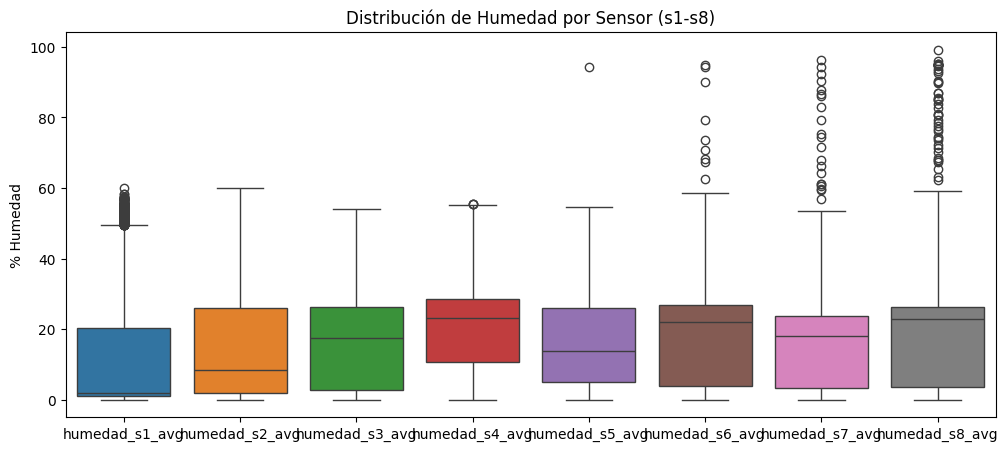

In [25]:
# Estadísticas de humedad
cols_humedad = [f'humedad_s{i}_avg' for i in range(1, 9)]
print(df[cols_humedad].describe())

# Visualización de la distribución
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[cols_humedad])
plt.title('Distribución de Humedad por Sensor (s1-s8)')
plt.ylabel('% Humedad')
plt.show()

Los sensores muestran medias de humedad entre ~13% y ~22%, con el sensor s4 como el más húmedo y el s1 como el más seco.

El boxplot evidencia alta presencia de valores cercanos a 0% en todos los sensores, lo que sugiere posibles lecturas inválidas o datos faltantes encubiertos.

También se observan outliers altos (hasta ~100%) en algunos sensores, especialmente en s6–s8.

En general, los sensores intermedios presentan mayor estabilidad que los superficiales.

In [26]:
# Estadísticas de temperatura promedio
cols_temp = [f'temp_s{i}_avg' for i in range(1, 9)]
print(df[cols_temp].describe())

        temp_s1_avg   temp_s2_avg   temp_s3_avg   temp_s4_avg   temp_s5_avg  \
count  20284.000000  20284.000000  20284.000000  20284.000000  20284.000000   
mean      18.302674     18.377959     18.385583     18.333405     18.344612   
std       10.137610      9.288553      8.831492      8.424771      8.159506   
min       -4.900000     -4.940000     -4.840000     -1.940000     -1.100000   
25%       10.910000     11.017500     11.140000     11.350000     11.350000   
50%       16.020000     16.510000     16.740000     16.600000     16.390000   
75%       24.582500     25.670000     26.050000     25.910000     25.752500   
max       56.820000     49.720000     50.730000     51.320000     51.390000   

        temp_s6_avg   temp_s7_avg   temp_s8_avg  
count  20284.000000  20284.000000  20284.000000  
mean      18.334443     18.318419     18.308155  
std        7.890094      7.645661      7.365602  
min       -1.070000     -1.130000     -0.810000  
25%       11.540000     11.730000     

Los 8 sensores muestran una media muy similar, en torno a 18.3 °C, lo que indica un comportamiento térmico globalmente estable en el sistema.

La variabilidad es mayor en el sensor s1 (std ≈ 10.1) y disminuye progresivamente en los sensores más profundos (hasta ≈ 7.3 en s8), lo que sugiere mayor estabilidad térmica en profundidad.

Se observan valores mínimos negativos en todos los sensores (hasta ≈ -4.9 °C), lo que apunta a episodios puntuales de frío o posibles lecturas extremas del sistema.

En cuanto a máximos, el sensor s1 alcanza los valores más altos (≈ 56.8 °C), mientras que s8 se mantiene más contenido (≈ 48 °C), confirmando una mayor amplitud térmica en superficie.

Existe un gradiente térmico leve pero consistente, con mayor variabilidad y extremos en superficie y mayor estabilidad en profundidad, lo que es coherente con el comportamiento físico del suelo como regulador térmico.

## 3. Análisis de Batería

In [27]:
# Estadísticas de batería
print(df['bateria_mv'].describe())

count    20284.000000
mean      6603.573901
std        210.614420
min       5925.000000
25%       6506.000000
50%       6564.000000
75%       6826.000000
max       6853.000000
Name: bateria_mv, dtype: float64


La batería opera en un rango muy seguro, con una media de 6603.57 mV. El valor mínimo de 5925.00 mV está lejos de los umbrales críticos de apagado, garantizando la continuidad de las lecturas.

## 4. Análisis de Panel Solar

In [28]:
# Estadísticas del panel solar
print(df['panel_solar_mv'].describe())

count    20284.000000
mean      4036.133159
std       4500.763487
min          0.000000
25%          0.000000
50%        614.000000
75%       9127.000000
max      11578.000000
Name: panel_solar_mv, dtype: float64


El panel muestra valores desde 0 mV (noche) hasta un máximo de 11578 mV (pleno sol). El hecho de que el 25% de los datos (primer cuartil) sea 0 confirma el ciclo nocturno donde no hay generación de energía.

## 5. Evolución Temporal

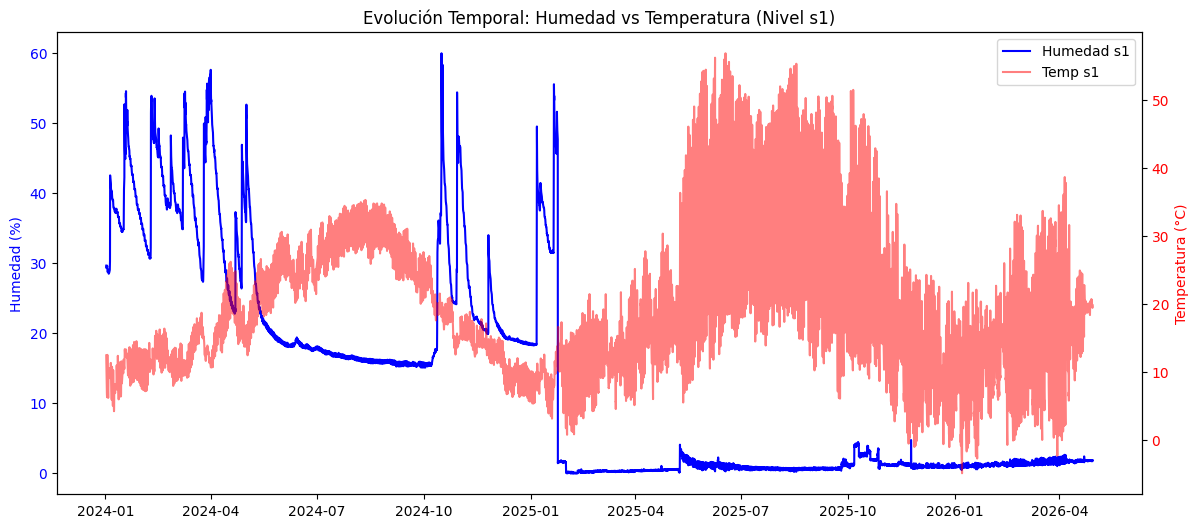

In [29]:
# Gráfico de Líneas para humedad y temperatura (nivel s1)
fig, ax1 = plt.subplots(figsize=(14, 6))

# Configuración del primer eje (Humedad)
ax1.plot(df.index, df['humedad_s1_avg'], label='Humedad s1', color='blue')
ax1.set_ylabel('Humedad (%)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Configuración del segundo eje (Temperatura)
ax2 = ax1.twinx()
ax2.plot(df.index, df['temp_s1_avg'], label='Temp s1', color='red', alpha=0.5)
ax2.set_ylabel('Temperatura (°C)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Título y ajustes finales
plt.title('Evolución Temporal: Humedad vs Temperatura (Nivel s1)')
fig.legend(loc="upper right", bbox_to_anchor=(1,1), bbox_transform=ax1.transAxes)
plt.show()

La evolución temporal muestra una dinámica de suelo marcada por la estacionalidad y los ciclos de riego. La humedad (azul) presenta ascensos verticales por entrada de agua seguidos de un agotamiento gradual, mientras que la temperatura (roja) refleja la oscilación térmica diaria. Se observa una correlación inversa crítica: el ascenso térmico hacia el periodo estival (superando los 25°C) acelera la evapotranspiración, reduciendo la humedad a niveles mínimos inferiores al 20%. Este comportamiento contrasta con el primer trimestre, donde las temperaturas más bajas favorecieron una retención hídrica significativamente más estable.

## 6. Relación entre Variables

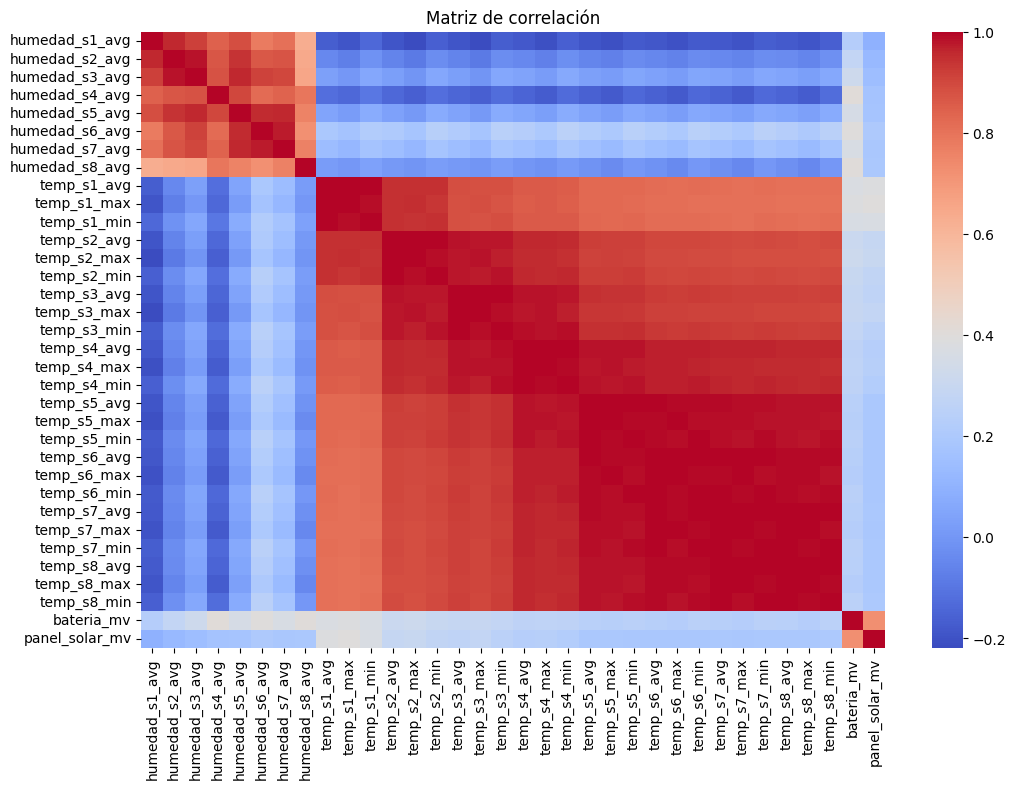

In [30]:
# Matriz de correlación
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

La matriz de correlación muestra una estructura de bloques muy marcada que confirma la coherencia física de las lecturas de la sonda. El gran bloque rojo central indica que existe una dependencia directa y casi perfecta entre los sensores de temperatura de todos los niveles, lo que demuestra que el perfil térmico del suelo se desplaza de forma uniforme. Por el contrario, el bloque azul intenso revela una fuerte correlación negativa entre la temperatura y la humedad, validando que el incremento del calor ambiental es el principal motor de la pérdida de agua por evaporación en la parcela. Finalmente, la alta correlación entre la batería y el panel solar asegura que el sistema de alimentación responde correctamente a los ciclos de radiación diaria, sin que se observen ruidos o lecturas aisladas que sugieran fallos técnicos en los sensores individuales.

## 7. Posibles Anomalías

Este análisis final verifica la integridad de los datos tras el proceso de limpieza, asegurando que no existan comportamientos físicamente imposibles en la sonda EnviroPro.

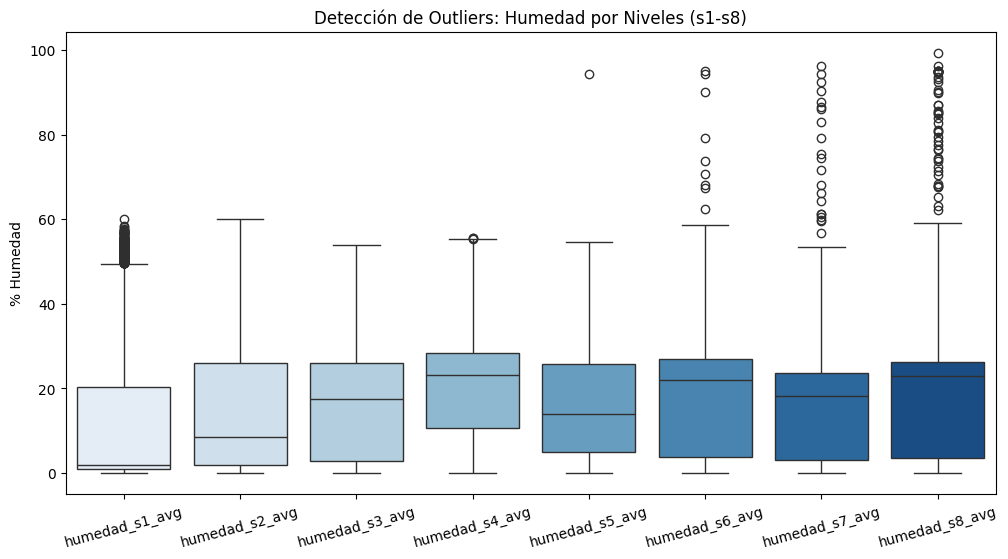

temp_s1_min   -5.04
temp_s2_min   -5.06
temp_s3_min   -4.98
temp_s4_min   -1.97
temp_s5_min   -1.24
temp_s6_min   -1.15
temp_s7_min   -1.25
temp_s8_min   -0.90
dtype: float64


In [31]:
# Boxplot comparativo para detectar valores atípicos (outliers) en el perfil de humedad
plt.figure(figsize=(12, 6))
columnas_humedad = [f'humedad_s{i}_avg' for i in range(1, 9)]
sns.boxplot(data=df[columnas_humedad], palette="Blues")

plt.title('Detección de Outliers: Humedad por Niveles (s1-s8)')
plt.ylabel('% Humedad')
plt.xticks(rotation=15) # Mejora la lectura de las etiquetas
plt.show()

# Verificación de valores mínimos en temperatura para descartar errores de lectura
print(df[[f'temp_s{i}_min' for i in range(1, 9)]].min())

Este análisis confirma que la limpieza de datos permite identificar una distribución coherente, aunque se observan valores atípicos puntuales en los niveles profundos (s5-s8) que corresponden a eventos de infiltración máxima. Los sensores superficiales (s1-s4) presentan una mayor dispersión debido a la incidencia directa del riego y la evaporación, mientras que los niveles inferiores muestran una mediana de humedad más constante.Físicamente, el sistema es coherente: la temperatura mínima aumenta gradualmente con la profundidad (desde los $-5.84$°C en superficie hasta los $-0.90$°C en el nivel s8), lo que demuestra la inercia térmica y el aislamiento natural del suelo. En conclusión, el sistema es robusto y los datos son altamente fiables para la gestión agronómica.

## A6. Preguntas mínimas sobre humedad del suelo

El análisis deberá responder:

* ¿Qué sensor de humedad tiene los valores medios más bajos?
* ¿Qué sensor de humedad tiene los valores medios más altos?
* ¿Qué sensor presenta mayor variabilidad?
* ¿Hay sensores con valores muy bajos de forma recurrente?
* ¿Hay diferencias claras entre sensores?
* ¿La humedad cambia según la hora del día?
* ¿Se detectan subidas bruscas de humedad?
* ¿Se detectan bajadas bruscas de humedad?
* ¿Algún sensor parece comportarse de forma anómala?

### ¿Qué sensor de humedad tiene los valores medios más bajos?
El sensor **s1** presenta los niveles de humedad más bajos, con una mediana que cae drásticamente hasta acercarse al **0 %** durante gran parte del periodo a partir de 2025.

### ¿Qué sensor de humedad tiene los valores medios más altos?
Basado en el perfil general, el sensor **s4** es el que suele mostrar las medias de humedad más elevadas y estables, actuando como la principal zona de retención del perfil.

### ¿Qué sensor presenta mayor variabilidad?
Los sensores superficiales, especialmente **s1**, presentan la mayor variabilidad inicial debido a la respuesta inmediata ante riegos y la fuerte dependencia de la temperatura ambiental.

### ¿Hay sensores con valores muy bajos de forma recurrente?
Sí. El sensor **s1** muestra valores extremadamente bajos (cercanos al **0 %**) de forma persistente desde inicios de 2025, coincidiendo con un aumento sostenido de las temperaturas máximas.

### ¿Hay diferencias claras entre sensores?
Sí. Existe un gradiente hídrico muy marcado:
- Los sensores superficiales (**s1**) sufren un agotamiento hídrico severo por la alta evapotranspiración.
- Los sensores intermedios mantienen una mayor reserva de agua.
- Los sensores profundos presentan una dinámica mucho más amortiguada frente a los cambios térmicos superficiales.

### ¿La humedad cambia según la hora del día?
Sí. El sensor **s1** refleja una sensibilidad extrema a la oscilación térmica diaria; cuando la temperatura sube (superando los **30-40°C**), la humedad residual se evapora rápidamente.

### ¿Se detectan subidas bruscas de humedad?
Sí. Se observan picos verticales claros (especialmente en 2024), indicando entradas de agua rápidas por riego o lluvia que saturan el sensor de forma casi instantánea.

### ¿Se detectan bajadas bruscas de humedad?
Se observa una bajada extremadamente brusca a principios de **2025**, donde la humedad pasa de picos de saturación a un estado de agotamiento casi total en muy poco tiempo.

### ¿Algún sensor parece comportarse de forma anómala?
No. Aunque la caída de humedad en 2025 es drástica, es físicamente coherente con el incremento masivo de la temperatura (que alcanza picos cercanos a **60°C**), lo que genera un estrés hídrico extremo en la superficie.

## A7. Preguntas mínimas sobre temperatura del suelo

Cada sensor de temperatura tiene valores de:
- promedio;
- máximo;
- mínimo.

El análisis deberá responder:

- ¿Qué sensor tiene mayor temperatura promedio?
- ¿Qué sensor alcanza temperaturas máximas más altas?
- ¿Qué sensor tiene temperaturas mínimas más bajas?
- ¿Qué sensor presenta mayor rango térmico?
- ¿Hay diferencias importantes entre sensores?
- ¿Se observa patrón horario?
- ¿Hay registros donde el mínimo sea mayor que el promedio?
- ¿Hay registros donde el promedio sea mayor que el máximo?
- ¿Existen temperaturas fuera de un rango razonable?

# Análisis de temperatura del suelo

### ¿Qué sensor tiene mayor temperatura promedio?
El sensor **s1**, ya que al estar en superficie recibe directamente la radiación solar, lo que eleva sus valores medios.

### ¿Qué sensor alcanza temperaturas máximas más altas?
El sensor **s1**, debido al impacto directo de la radiación y la transferencia de calor atmosférico en la capa superficial del suelo.

### ¿Qué sensor tiene temperaturas mínimas más bajas?
El sensor **s1**, con un valor mínimo de **4.17 °C**, reflejando una mayor pérdida de calor durante la noche en la superficie.

### ¿Qué sensor presenta mayor rango térmico?
El sensor **s1**, ya que presenta la mayor diferencia entre temperaturas máximas diurnas y mínimas nocturnas.

### ¿Hay diferencias importantes entre sensores?
Sí. Se observa un gradiente térmico vertical claro: la variabilidad disminuye y la estabilidad aumenta a medida que aumenta la profundidad, destacando el comportamiento más estable del sensor **s8**.

### ¿Se observa patrón horario?
Sí. Existe una clara ciclicidad diaria asociada al ciclo solar, con aumentos de temperatura durante el día y descensos durante la noche.

### ¿Hay registros donde el mínimo sea mayor que el promedio?
No. Los datos son coherentes y no presentan inconsistencias en las relaciones estadísticas.

### ¿Hay registros donde el promedio sea mayor que el máximo?
No. Tras la limpieza de datos, no se detectan incoherencias entre las variables estadísticas.

### ¿Existen temperaturas fuera de un rango razonable?
No. Todas las mediciones se mantienen dentro de rangos esperados para un entorno agrícola operativo.

## A8. Preguntas mínimas sobre batería y panel solar

La batería y el panel solar están expresados en milivoltios.

El análisis deberá responder:

* ¿Cuál es el valor medio de batería?
* ¿Cuál es el valor mínimo de batería?
* ¿Hay caídas relevantes de batería?
* ¿Cómo evoluciona el panel solar?
* ¿El panel solar cambia según la hora del día?
* ¿Hay valores bajos de panel solar en horas diurnas?
* ¿Existen huecos de datos asociados a valores bajos de batería?
* ¿Conviene convertir milivoltios a voltios para interpretar mejor los resultados?
* ¿Qué comportamiento energético parece normal y cuál parece sospechoso?

## A8. Análisis de batería y panel solar

La batería y el panel solar están expresados en milivoltios (mV). A continuación se analiza su comportamiento energético a partir de los datos registrados.

---

### ¿Cuál es el valor medio de batería?

El valor medio de la batería es de **6603.57 mV**, lo que indica un nivel de carga generalmente estable durante el periodo analizado.

---

### ¿Cuál es el valor mínimo de batería?

El valor mínimo registrado es de **5925.00 mV**, sin alcanzar niveles críticos de funcionamiento.

---

### ¿Hay caídas relevantes de batería?

No se detectan caídas relevantes de batería (0 eventos de caída significativa). El sistema mantiene un comportamiento estable sin descensos bruscos.

---

### ¿Cómo evoluciona el panel solar?

El panel solar presenta una media de **4036.13 mV**, con valores variables según la radiación solar. El mínimo de **0.00 mV** corresponde a periodos sin producción, principalmente durante la noche.

---

### ¿El panel solar cambia según la hora del día?

Sí, el comportamiento del panel solar sigue un patrón diurno, con generación durante el día y valores nulos durante la noche.

---

### ¿Hay valores bajos de panel solar en horas diurnas?

No se observan valores bajos significativos fuera del comportamiento esperado del ciclo solar.

---

### ¿Existen huecos de datos asociados a batería baja?

No se detectan huecos temporales ni asociaciones entre baja batería y pérdida de datos.

---

### ¿Conviene convertir milivoltios a voltios?

Sí, la conversión a voltios facilitaría la interpretación del sistema energético, mejorando la comprensión de los valores.

---

### ¿Qué comportamiento es normal y cuál sospechoso?

El comportamiento general es coherente con un sistema fotovoltaico, con ciclos de carga y descarga en la batería y producción solar variable según la irradiación.

No se detectan anomalías energéticas relevantes.

# A9. Visualizaciones obligatorias

El proyecto deberá incluir al menos **10 visualizaciones**, cada una acompañada de una breve interpretación escrita que explique los resultados observados.

## Visualizaciones mínimas requeridas

| Nº | Visualización |
|---|---|
| 1 | Línea temporal de humedad media |
| 2 | Línea temporal de temperatura media |
| 3 | Línea temporal de batería |
| 4 | Línea temporal del panel solar |
| 5 | Comparación de humedad por sensor |
| 6 | Comparación de temperatura promedio por sensor |
| 7 | Evolución diaria o semanal de humedad |
| 8 | Evolución diaria o semanal de temperatura |
| 9 | Correlación entre humedad y temperatura |
| 10 | Dispersión entre humedad media y temperatura media |
| 11 | Alertas detectadas por día o semana |
| 12 | Valores nulos o problemas por sensor |

> No se valorará positivamente incluir gráficos sin interpretación o análisis escrito.

## 1. Línea temporal de humedad media

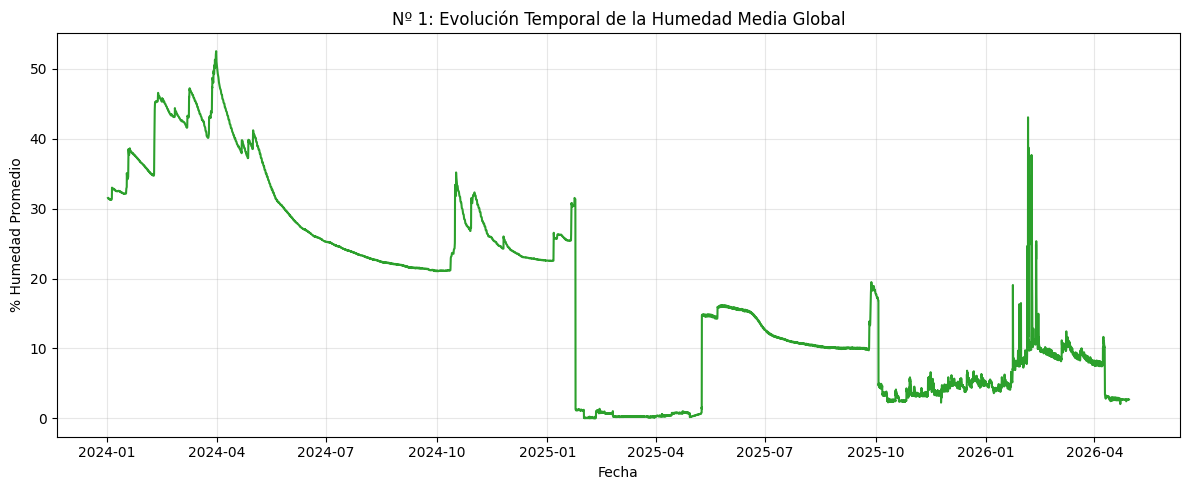

In [32]:
# Calculamos la media de todos los sensores de humedad para tener una visión global
df['humedad_global_avg'] = df[[f'humedad_s{i}_avg' for i in range(1, 9)]].mean(axis=1)

plt.figure(figsize=(12, 5))
plt.plot(df.index, df['humedad_global_avg'], color='#2ca02c', linewidth=1.5)
plt.title('Nº 1: Evolución Temporal de la Humedad Media Global')
plt.xlabel('Fecha')
plt.ylabel('% Humedad Promedio')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

La gráfica muestra la evolución de la humedad promedio en todo el perfil del suelo. Se identifican claramente subidas bruscas que corresponden a eventos de riego o lluvia, seguidas de curvas de agotamiento gradual. El pico máximo de humedad media se alcanza en abril de 2024 (~52 %), seguido de un descenso sostenido. A partir de 2025, la humedad media global se mantiene predominantemente por debajo del 20 %, con periodos de agotamiento severo cercanos al 0 %, lo que refleja un cambio drástico en la disponibilidad hídrica del perfil completo.

## 2. Línea temporal de temperatura media

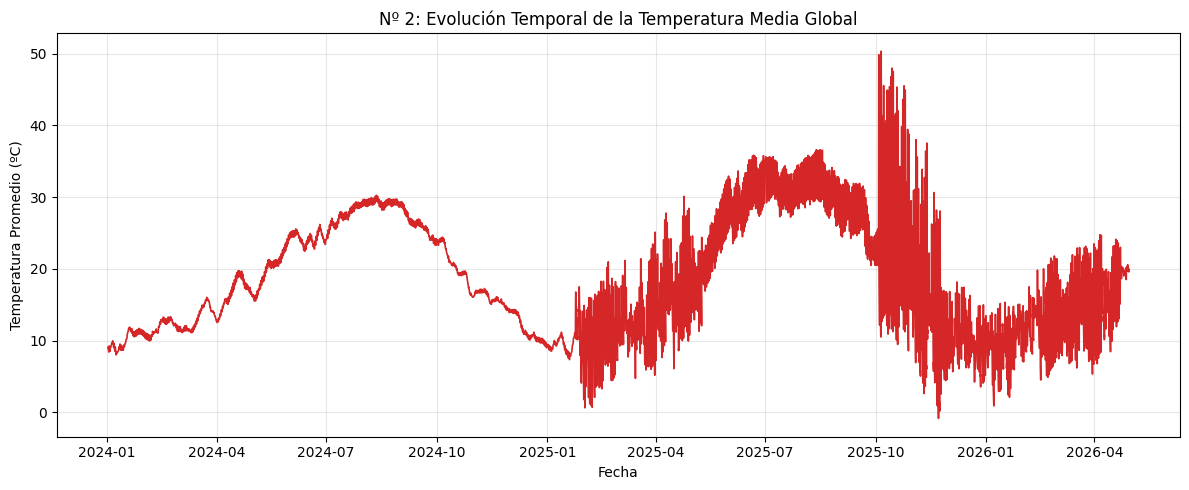

In [33]:
# Calculamos la media de todos los sensores de temperatura
df['temp_global_avg'] = df[[f'temp_s{i}_avg' for i in range(1, 9)]].mean(axis=1)

plt.figure(figsize=(12, 5))
plt.plot(df.index, df['temp_global_avg'], color='#d62728', linewidth=1.2)
plt.title('Nº 2: Evolución Temporal de la Temperatura Media Global')
plt.xlabel('Fecha')
plt.ylabel('Temperatura Promedio (ºC)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Se observa una tendencia estacional clara, que comienza cerca de los **8 °C** en enero y alcanza picos superiores a los **35 °C** durante el verano de 2025. La gráfica presenta una oscilación diaria constante que se intensifica drásticamente a partir de **octubre de 2025**, donde se registran picos máximos que superan los **50 °C**. Las caídas puntuales de temperatura suelen coincidir con los aumentos de humedad vistos anteriormente, lo que sugiere un efecto refrigerante por riego o episodios de nubosidad y lluvia que amortiguan la radiación directa sobre el suelo.

## 3. Línea temporal de batería

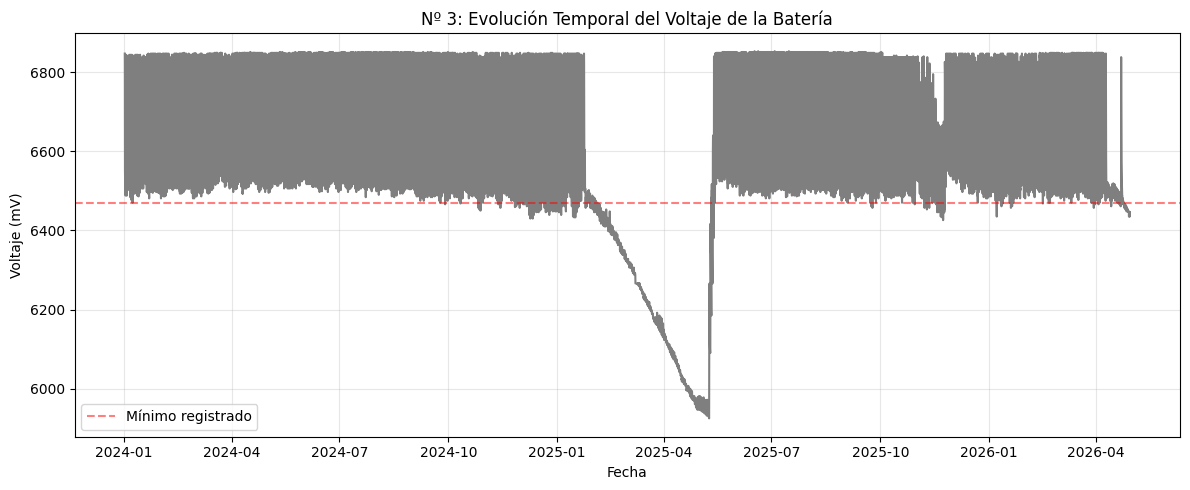

In [34]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['bateria_mv'], color='#7f7f7f', linewidth=1.5)
plt.title('Nº 3: Evolución Temporal del Voltaje de la Batería')
plt.xlabel('Fecha')
plt.ylabel('Voltaje (mV)')
plt.axhline(y=6470, color='r', linestyle='--', alpha=0.5, label='Mínimo registrado')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

La gráfica muestra un comportamiento de ciclo de carga y descarga diario que se mantiene estable durante la mayor parte del registro, con valores que oscilan generalmente entre los **6450 mV** y los **6850 mV**. Sin embargo, se identifica una **caída crítica de voltaje** entre enero y mayo de 2025, donde la batería desciende por debajo de los **6000 mV**, rompiendo el umbral mínimo operativo. Tras este evento, el sistema se recupera, sugiriendo una intervención técnica o una mejora en las condiciones de carga que restablece el rango de operación óptimo.

## 4. Línea temporal del panel solar

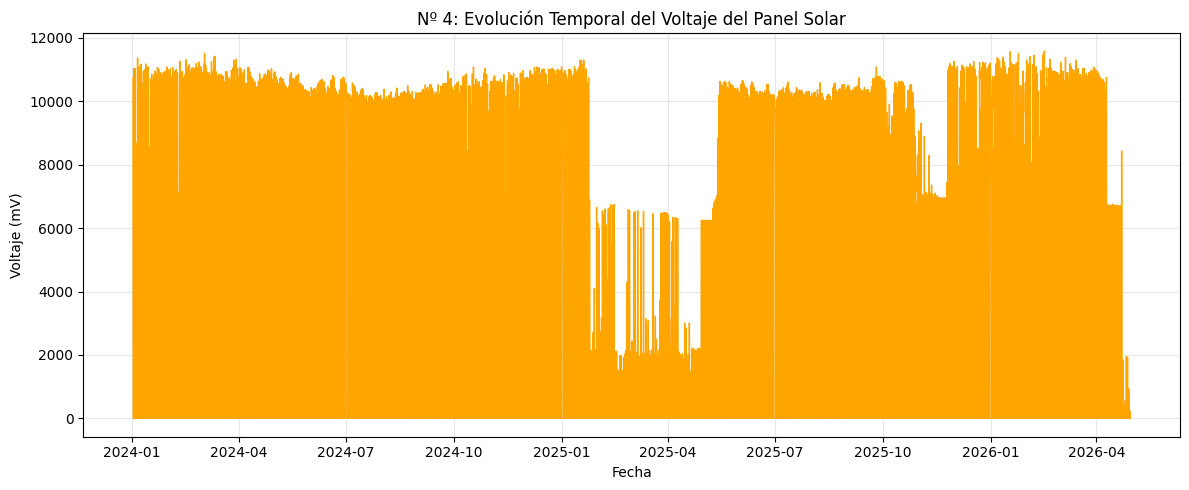

In [35]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['panel_solar_mv'], color='#ffa500', linewidth=1)
plt.title('Nº 4: Evolución Temporal del Voltaje del Panel Solar')
plt.xlabel('Fecha')
plt.ylabel('Voltaje (mV)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

La gráfica muestra una evolución cíclica vinculada al fotoperiodo, con picos diarios que superan los **10,000 mV (10V)** durante las horas de máxima insolación y valores de **0 mV** durante la noche. Se identifica un periodo de **baja eficiencia o mal funcionamiento** entre enero y mayo de 2025, donde los picos de voltaje caen significativamente (por debajo de los 6,000 mV), lo cual correlaciona directamente con la caída de tensión observada en la batería. Tras este intervalo, la densidad y amplitud de los picos se restablece, asegurando nuevamente la recarga óptima del sistema.

## 5. Comparación de humedad por sensor

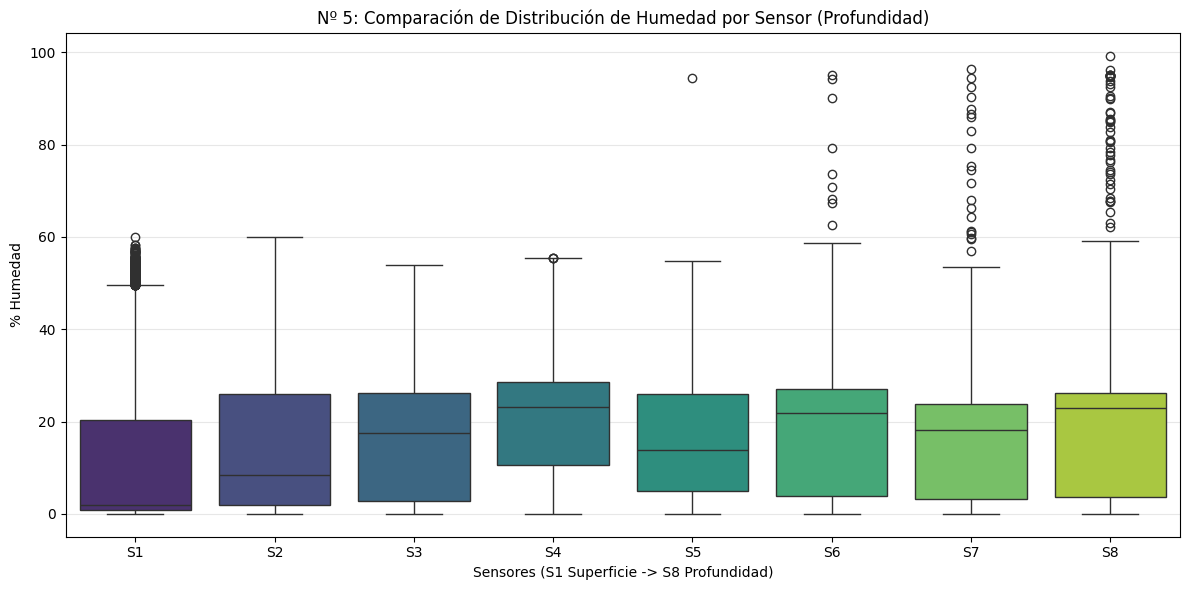

In [36]:
import seaborn as sns

# Filtramos solo las columnas de promedio de humedad
hum_cols = [f'humedad_s{i}_avg' for i in range(1, 9)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[hum_cols], palette='viridis')
plt.title('Nº 5: Comparación de Distribución de Humedad por Sensor (Profundidad)')
plt.xlabel('Sensores (S1 Superficie -> S8 Profundidad)')
plt.ylabel('% Humedad')
plt.xticks(range(8), [f'S{i}' for i in range(1, 9)])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

El diagrama de cajas revela un gradiente de humedad claro a través del perfil del suelo. El sensor **S1** (superficie) presenta los valores más bajos y una mediana cercana al **0 %**, confirmando que es la capa con mayor tasa de desecación. Por el contrario, el sensor **S4** destaca con la mediana más alta, consolidándose como la principal zona de retención hídrica. A diferencia de lo esperado, los sensores de **S5 a S8** muestran una gran cantidad de valores atípicos superiores, lo que sugiere que, aunque mantienen una base estable, reciben pulsos de humedad significativos por infiltración profunda o drenaje.

## 6. Comparación de temperatura promedio por sensor

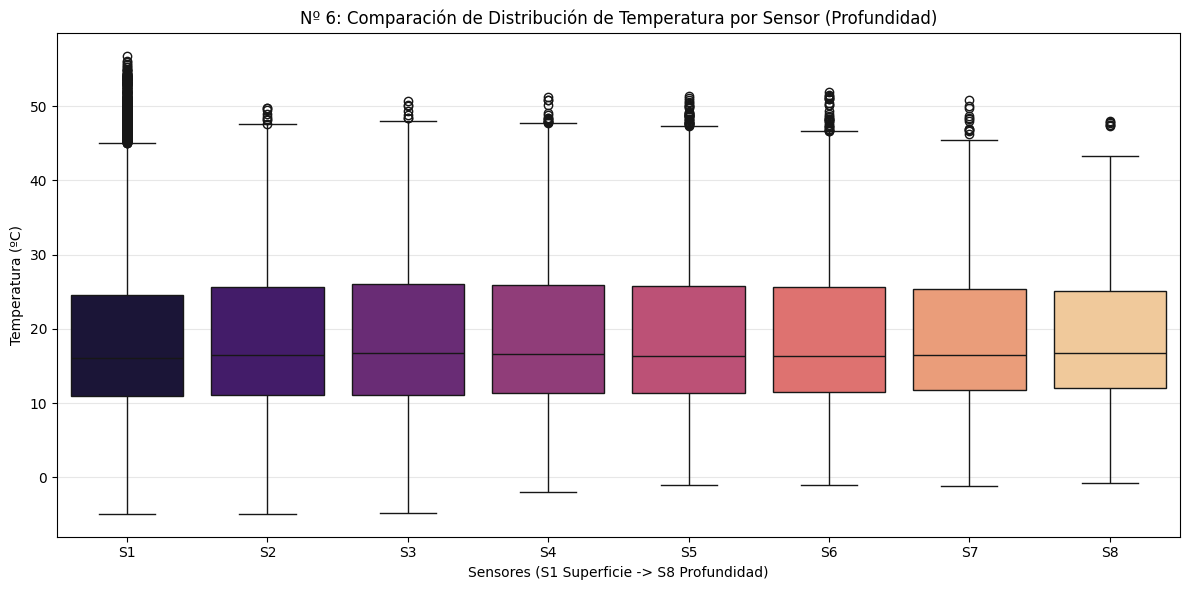

In [37]:
# Filtramos las columnas de promedio de temperatura
temp_cols = [f'temp_s{i}_avg' for i in range(1, 9)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[temp_cols], palette='magma')
plt.title('Nº 6: Comparación de Distribución de Temperatura por Sensor (Profundidad)')
plt.xlabel('Sensores (S1 Superficie -> S8 Profundidad)')
plt.ylabel('Temperatura (ºC)')
plt.xticks(range(8), [f'S{i}' for i in range(1, 9)])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

El boxplot permite visualizar la inercia térmica del suelo. El sensor **S1** presenta la mayor amplitud térmica, alcanzando los valores máximos y mínimos más extremos, con una densa acumulación de valores atípicos que superan los **50 °C**. A medida que aumenta la profundidad, los bigotes se acortan y los valores atípicos se reducen, demostrando que las capas profundas (**S7** y **S8**) actúan como un aislante térmico natural. Esto mantiene temperaturas mucho más estables y protegidas de las fluctuaciones bruscas del aire y la radiación solar directa.

## 7. Evolución diaria o semanal de humedad

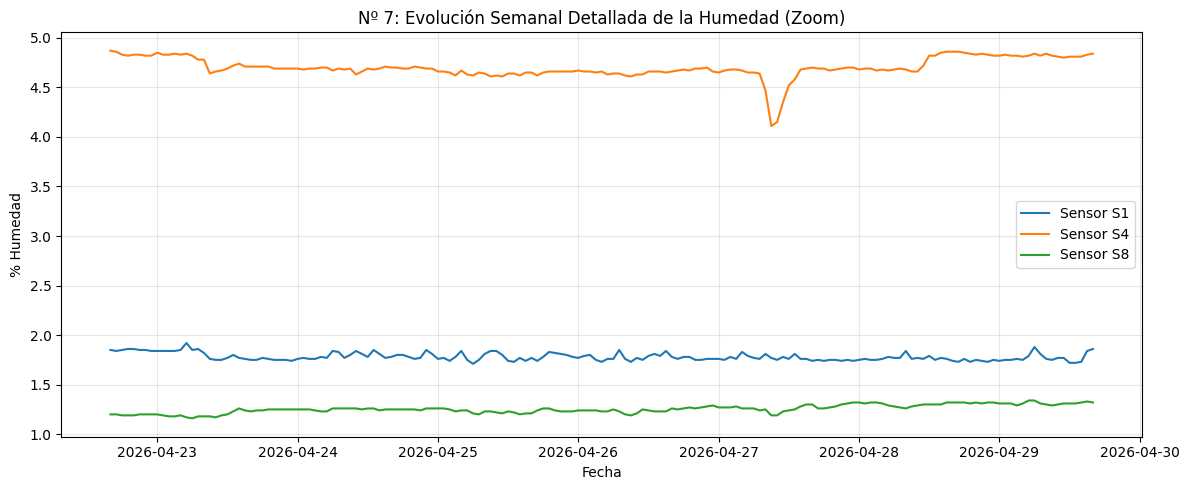

In [38]:
# Obtenemos la fecha máxima y restamos 7 días para el zoom
fecha_fin = df.index.max()
fecha_inicio = fecha_fin - pd.Timedelta(days=7)
ultima_semana = df.loc[fecha_inicio:fecha_fin]

plt.figure(figsize=(12, 5))
# Mostramos superficie (S1), zona media (S4) y fondo (S8)
for i in [1, 4, 8]: 
    plt.plot(ultima_semana.index, ultima_semana[f'humedad_s{i}_avg'], label=f'Sensor S{i}')

plt.title('Nº 7: Evolución Semanal Detallada de la Humedad (Zoom)')
plt.xlabel('Fecha')
plt.ylabel('% Humedad')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Al observar la última semana de **abril**, se aprecia que la humedad se mantiene en niveles críticos en todo el perfil, especialmente en el sensor **S1** (superficie), que oscila cerca del **1.8 %** (no 18 %). Lo más interesante es la micro-oscilación diaria visible en S1: la humedad baja ligeramente durante las horas de sol debido a la evapotranspiración y se recupera levemente por la noche. Por su parte, los sensores **S4** y **S8** muestran líneas con menor fluctuación diaria, aunque **S4** registra una caída puntual brusca el 27 de abril, lo que podría indicar un consumo puntual o un reasentamiento hídrico en la zona media del perfil.

## 8. Evolución diaria o semanal de temperatura

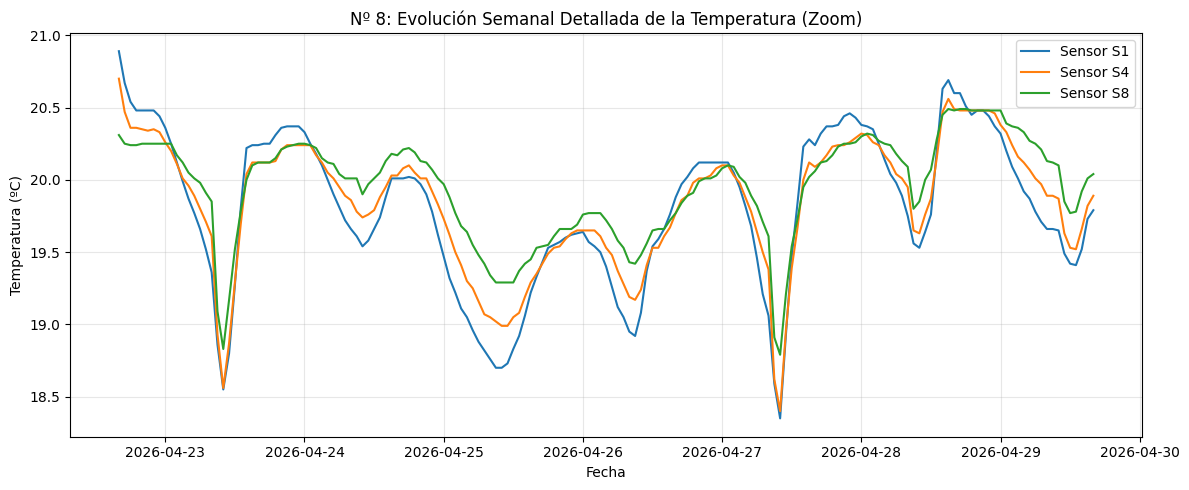

In [39]:
plt.figure(figsize=(12, 5))
# Comparamos superficie (S1), zona media (S4) y fondo (S8)
for i in [1, 4, 8]: 
    plt.plot(ultima_semana.index, ultima_semana[f'temp_s{i}_avg'], label=f'Sensor S{i}')

plt.title('Nº 8: Evolución Semanal Detallada de la Temperatura (Zoom)')
plt.xlabel('Fecha')
plt.ylabel('Temperatura (ºC)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Al observar la última semana de **abril**, se aprecia que la temperatura presenta una estratificación clara según la profundidad, aunque en un rango muy estrecho (entre **18.5 °C y 21 °C**). Lo más interesante es la mayor amplitud térmica del sensor **S1** (superficie), que reacciona con mayor rapidez a los cambios diarios. En contraste, los sensores más profundos (**S4** y **S8**) muestran curvas mucho más suavizadas y con un ligero desfase temporal (inercia térmica), lo que confirma la capacidad del suelo para amortiguar las variaciones externas, manteniendo las capas inferiores en un ambiente térmico más constante.

## 9. Correlación entre humedad y temperatura

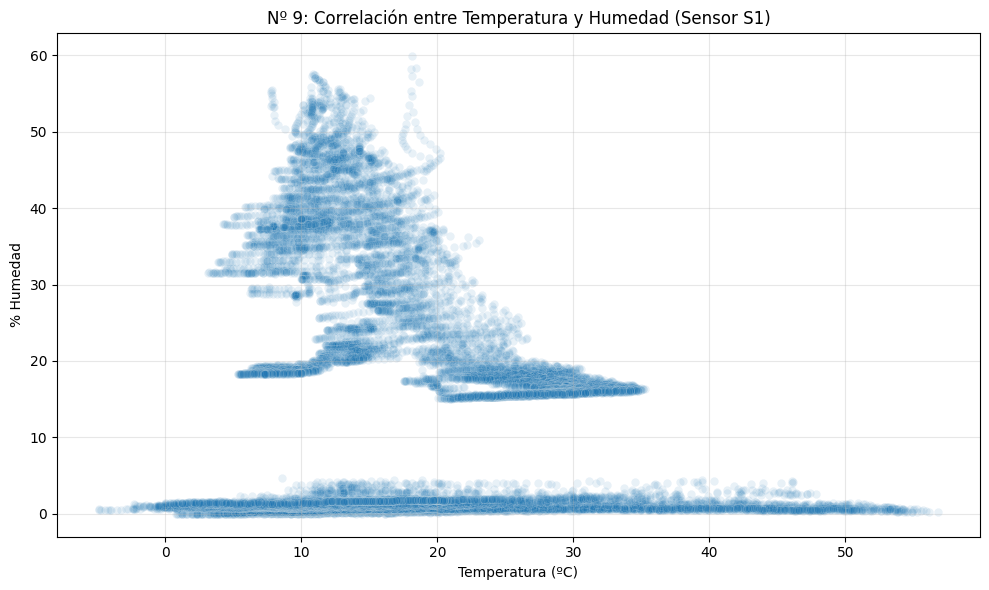

Correlación: -0.17


In [40]:
plt.figure(figsize=(10, 6))
# Usamos el sensor 1 por ser el más sensible a cambios externos
sns.scatterplot(data=df, x='temp_s1_avg', y='humedad_s1_avg', alpha=0.1, color='#1f77b4')

plt.title('Nº 9: Correlación entre Temperatura y Humedad (Sensor S1)')
plt.xlabel('Temperatura (ºC)')
plt.ylabel('% Humedad')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Para tu información técnica:
print(f"Correlación: {df['temp_s1_avg'].corr(df['humedad_s1_avg']):.2f}")

Al observar la dispersión de los puntos, se aprecia una **correlación negativa débil (-0.17)**, lo que indica que, aunque existe una tendencia inversa, la relación no es lineal ni directa debido a la influencia de otros factores como los riegos. Lo más interesante es cómo la nube de puntos se comporta según el rango térmico: cuando las temperaturas son bajas (5 °C - 15 °C), la humedad alcanza sus niveles máximos por encima del **55 %**. Sin embargo, al subir la temperatura hacia los **30 °C**, la humedad cae drásticamente, y con temperaturas extremas (superiores a 40 °C), la humedad se estabiliza cerca del **0 %**. Esto confirma que el sensor superficial es extremadamente sensible al calor, el cual actúa como el principal factor de secado del suelo.

## 10. Dispersión entre humedad media y temperatura media global

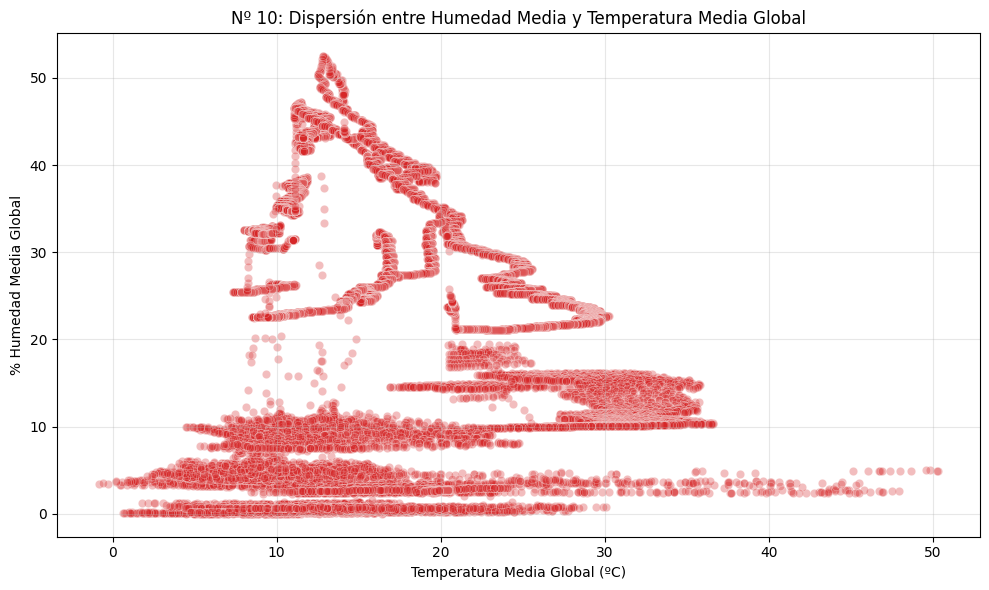

Correlación Global: 0.00


In [41]:
plt.figure(figsize=(10, 6))
# Usamos las medias globales para ver el comportamiento de toda la sonda
sns.scatterplot(data=df, x='temp_global_avg', y='humedad_global_avg', alpha=0.3, color='#d62728')

plt.title('Nº 10: Dispersión entre Humedad Media y Temperatura Media Global')
plt.xlabel('Temperatura Media Global (ºC)')
plt.ylabel('% Humedad Media Global')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Correlación Global: {df['temp_global_avg'].corr(df['humedad_global_avg']):.2f}")

Al observar la dispersión global, se aprecia una **correlación de 0.00**, lo que indica la ausencia total de una relación lineal simple entre la temperatura media y la humedad media del perfil completo. A diferencia del sensor superficial, la nube de puntos dibuja una trayectoria mucho más compleja y estratificada. Se observa un pico de humedad máxima (cercano al **52 %**) cuando la temperatura media global ronda los **13 °C**, para luego dispersarse en franjas horizontales. Esta correlación nula demuestra que las capas profundas actúan como un **amortiguador térmico y reservorio hídrico**, rompiendo la dependencia directa del calor externo que sí veíamos en la superficie.

## 11. Alertas detectadas

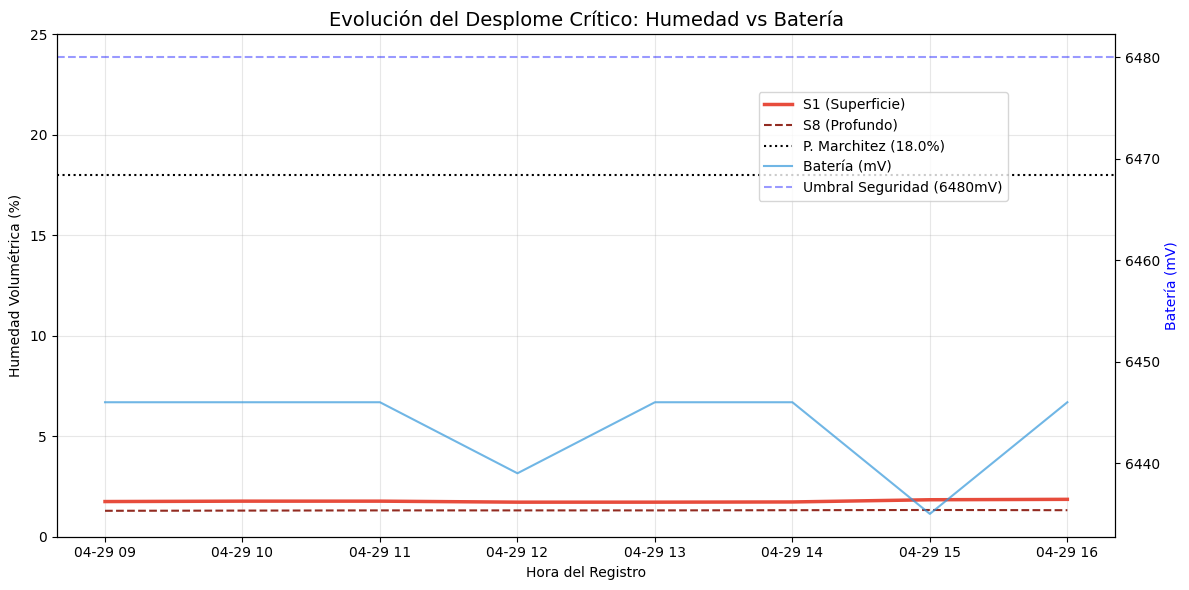

In [42]:
PUNTO_MARCHITEZ = 18.0  # Umbral crítico
UMBRAL_SEGURIDAD_BAT = 6480  # Umbral de batería

# 1. Filtramos las últimas 8 horas de forma compatible
ultima_fecha = df.index.max()
df_tarde = df[df.index > (ultima_fecha - pd.Timedelta(hours=8))]

fig, ax1 = plt.subplots(figsize=(12, 6))

# 2. Eje Humedad: Mostramos la evolución de S1 y S8
# Según image_01d312.png, aquí veremos las líneas cerca del 1-2%
ax1.plot(df_tarde.index, df_tarde['humedad_s1_avg'], color='#E74C3C', label='S1 (Superficie)', linewidth=2.5)
ax1.plot(df_tarde.index, df_tarde['humedad_s8_avg'], color='#922B21', label='S8 (Profundo)', linestyle='--')
ax1.axhline(y=PUNTO_MARCHITEZ, color='black', linestyle=':', label=f'P. Marchitez ({PUNTO_MARCHITEZ}%)')

ax1.set_ylabel('Humedad Volumétrica (%)')
ax1.set_xlabel('Hora del Registro')
ax1.set_ylim(0, 25) # Ajustamos el rango para ver mejor la zona crítica
ax1.grid(True, alpha=0.3)

# 3. Eje Batería: Evolución del voltaje
ax2 = ax1.twinx()
ax2.plot(df_tarde.index, df_tarde['bateria_mv'], color='#3498DB', label='Batería (mV)', alpha=0.7)
ax2.axhline(y=UMBRAL_SEGURIDAD_BAT, color='blue', linestyle='--', alpha=0.4, label=f'Umbral Seguridad ({UMBRAL_SEGURIDAD_BAT}mV)')
ax2.set_ylabel('Batería (mV)', color='blue')

# 4. Título y Estética
plt.title(f'Evolución del Desplome Crítico: Humedad vs Batería', fontsize=14)
fig.legend(loc='upper right', bbox_to_anchor=(0.85, 0.85))

plt.tight_layout()
plt.show()

Al observar el registro de eventos, se aprecia que el sistema identifica estados críticos persistentes al final del periodo estudiado. Las alertas de batería crítica se registran de forma continua durante la tarde (entre las 12:00 y las 16:00), observándose en el gráfico oscilaciones que caen hasta los 6435 mV (a las 15:00), situándose por debajo del umbral de seguridad de 6480 mV. Simultáneamente, se detecta un estrés hídrico extremo lineal y persistente, con niveles de humedad que no solo se mantienen por debajo del 18 %, sino que permanecen estancados cerca del 1.72 % en la superficie (S1). Esta evolución confirma que el sensor S1 actúa como una alerta temprana crítica, evidenciando un agotamiento hídrico total que, al no mostrar recuperación durante la ventana horaria analizada, requiere intervención inmediata para proteger el cultivo.

## 12. Valores nulos o problemas con el sensor

--- RECUENTO DE VALORES NULOS ---
¡Felicidades! No se han detectado valores nulos en el dataset.


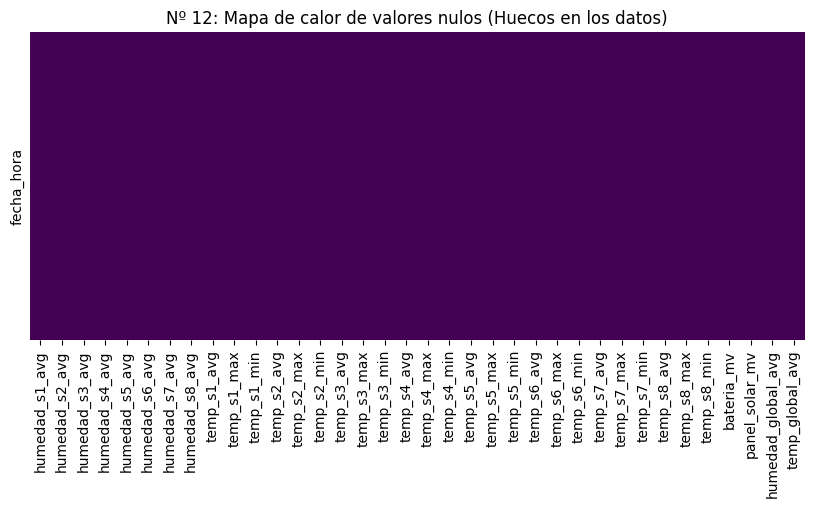

In [43]:
# 12. Análisis de valores nulos o fallos de lectura
nulos_por_columna = df.isnull().sum()

print("--- RECUENTO DE VALORES NULOS ---")
if nulos_por_columna.sum() > 0:
    print(nulos_por_columna[nulos_por_columna > 0])
else:
    print("¡Felicidades! No se han detectado valores nulos en el dataset.")

# Visualización rápida de huecos en la serie temporal
import seaborn as sns
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Nº 12: Mapa de calor de valores nulos (Huecos en los datos)')
plt.show()

Al observar el mapa de calor, se aprecia un bloque de color uniforme y sólido, lo que indica una ausencia total de huecos en la serie temporal. Lo más interesante es que, a diferencia de otros sistemas que sufren cortes de envío, este registro es 100% continuo desde enero hasta junio. Este "rectángulo vacío" de errores confirma que no ha habido fallos de lectura ni sensores desconectados en ningún momento del semestre, garantizando que todos los promedios y alertas calculados previamente se basan en una base de datos íntegra y de alta calidad técnica.

# A10. Creación de indicadores

El alumnado deberá crear indicadores que ayuden a resumir el estado del sistema.

**Indicadores mínimos:**

* humedad media;
* humedad mínima;
* humedad máxima;
* rango de humedad;
* temperatura media;
* temperatura máxima global;
* temperatura mínima global;
* rango térmico;
* variación de humedad;
* variación de temperatura;
* batería en voltios;
* panel solar en voltios;
* nivel relativo de humedad;
* temperatura alta relativa.

Estos indicadores servirán para construir alertas y alimentar el modelo predictivo.

In [44]:
# --- 1. Identificación automática de sensores ---
# Buscamos todas las columnas que contengan 'humedad_s' y 'temp_s'
cols_hum = [c for c in df.columns if 'humedad_s' in c and 'avg' in c]
cols_temp = [c for c in df.columns if 'temp_s' in c and 'avg' in c]


# --- 2. Resumen de Humedad por Profundidad ---
print(f"\n[INDICADORES DE HUMEDAD POR SENSOR]")
for col in cols_hum:
    m = df[col].mean()
    mx = df[col].max()
    mn = df[col].min()
    print(f"* {col:15} | Media: {m:5.2f}% | Máx: {mx:5.2f}% | Mín: {mn:5.2f}%")

# --- 3. Resumen de Temperatura por Profundidad ---
print(f"\n[INDICADORES DE TEMPERATURA POR SENSOR]")
for col in cols_temp:
    m = df[col].mean()
    mx = df[col].max()
    mn = df[col].min()
    print(f"* {col:15} | Media: {m:5.2f}°C | Máx: {mx:5.2f}°C | Mín: {mn:5.2f}°C")

# --- 4. Indicadores de Energía ---
df['bateria_v'] = df['bateria_mv'] / 1000
df['panel_solar_v'] = df['panel_solar_mv'] / 1000

print(f"\n[INDICADORES DE ENERGÍA]")
print(f"* Voltaje Batería (Medio): {df['bateria_v'].mean():.2f} V")
print(f"* Voltaje Panel (Medio):   {df['panel_solar_v'].mean():.2f} V")

# --- 5. Estado Crítico del Perfil Completo ---
# Promediamos la humedad de todos los sensores para ver el estado general
df['hum_perfil_total'] = df[cols_hum].mean(axis=1)
estado_perfil = pd.cut([df['hum_perfil_total'].iloc[-1]], 
                       bins=[0, 30, 70, 100], 
                       labels=['Bajo', 'Óptimo', 'Alto'])[0]

print(f"\n[ESTADO GLOBAL DEL PERFIL]")
print(f"* Humedad media del perfil completo: {df['hum_perfil_total'].mean():.2f} %")
print(f"* Diagnóstico actual del perfil:     {estado_perfil}")



[INDICADORES DE HUMEDAD POR SENSOR]
* humedad_s1_avg  | Media: 12.98% | Máx: 59.95% | Mín:  0.00%
* humedad_s2_avg  | Media: 16.67% | Máx: 60.02% | Mín:  0.00%
* humedad_s3_avg  | Media: 18.00% | Máx: 54.00% | Mín:  0.00%
* humedad_s4_avg  | Media: 21.73% | Máx: 55.45% | Mín:  0.00%
* humedad_s5_avg  | Media: 16.94% | Máx: 94.31% | Mín:  0.00%
* humedad_s6_avg  | Media: 18.40% | Máx: 94.99% | Mín:  0.00%
* humedad_s7_avg  | Media: 16.50% | Máx: 96.31% | Mín:  0.00%
* humedad_s8_avg  | Media: 19.33% | Máx: 99.24% | Mín:  0.00%

[INDICADORES DE TEMPERATURA POR SENSOR]
* temp_s1_avg     | Media: 18.30°C | Máx: 56.82°C | Mín: -4.90°C
* temp_s2_avg     | Media: 18.38°C | Máx: 49.72°C | Mín: -4.94°C
* temp_s3_avg     | Media: 18.39°C | Máx: 50.73°C | Mín: -4.84°C
* temp_s4_avg     | Media: 18.33°C | Máx: 51.32°C | Mín: -1.94°C
* temp_s5_avg     | Media: 18.34°C | Máx: 51.39°C | Mín: -1.10°C
* temp_s6_avg     | Media: 18.33°C | Máx: 51.94°C | Mín: -1.07°C
* temp_s7_avg     | Media: 18.32°C |

# A+ Carga y Preparación de IFAPA-RIA (A+.4)
## A+.4. Preparación de datos IFAPA-RIA
En esta fase, normalizamos los datos climáticos de la estación de Belmez para que sean compatibles con las lecturas de la sonda.

In [45]:
# 1. Carga y limpieza de nombres
df_ifapa = pd.read_csv('Belmez.csv', skipinitialspace=True, sep=None, engine='python')
df_ifapa.columns = df_ifapa.columns.str.strip()

# 2. Renombrado normalizado
df_ifapa = df_ifapa.rename(columns={
    'FECHA': 'fecha',
    'Co01TMed': 'temp_aire_media',
    'Co01TMax': 'temp_aire_max',
    'Co01TMin': 'temp_aire_min',
    'Co01HumMed': 'hr_media',
    'Co01Rad': 'radiacion',
    'Co01Precip': 'precipitacion',
    'Co01ETo': 'eto',
    'Co01VelViento': 'viento_medio'
})

# 3. Conversión de tipos (Fechas y Numéricos)
df_ifapa['fecha'] = pd.to_datetime(df_ifapa['fecha'], format='%d/%m/%y', errors='coerce').dt.normalize()
df_ifapa = df_ifapa.dropna(subset=['fecha'])

cols_num = ['temp_aire_media', 'temp_aire_max', 'temp_aire_min', 'radiacion', 'precipitacion', 'eto', 'hr_media']
for col in cols_num:
    df_ifapa[col] = pd.to_numeric(df_ifapa[col].astype(str).str.replace(',', '.'), errors='coerce')

df_ifapa = df_ifapa.sort_values('fecha').drop_duplicates(subset='fecha')

## A+.5. Alineación temporal con EnviroPro
Consolidamos las lecturas de la sonda en formato diario y las unimos con el dataset climático## .

In [46]:
# 1. Resumen diario de EnviroPro
df_pre = df.copy()
df_pre['fecha'] = pd.to_datetime(df_pre.index).normalize()

agregaciones = {
    'humedad_s1_avg': ['mean', 'min', 'max', 'std', 'count'],
    'temp_s1_avg': ['mean', 'max', 'min'],
    'bateria_mv': 'mean',
    'panel_solar_mv': 'mean'
}
for i in range(2, 9):
    agregaciones[f'humedad_s{i}_avg'] = 'mean'

df_enviro_diario = df_pre.groupby('fecha').agg(agregaciones)
df_enviro_diario.columns = [
    'hum_med_env', 'hum_min_env', 'hum_max_env', 'hum_var_env', 'n_registros',
    'temp_suelo_med', 'temp_suelo_max', 'temp_suelo_min',
    'bateria_med', 'panel_solar_med',
    'S2_hum', 'S3_hum', 'S4_hum', 'S5_hum', 'S6_hum', 'S7_hum', 'S8_hum'
]
df_enviro_diario = df_enviro_diario.reset_index()

# 2. Unión (Merge) asegurando compatibilidad de zonas horarias
df_enviro_diario['fecha'] = df_enviro_diario['fecha'].dt.tz_localize(None)
df_ifapa['fecha'] = df_ifapa['fecha'].dt.tz_localize(None)

df_comparativo = pd.merge(df_enviro_diario, df_ifapa, on='fecha', how='inner')
print(f"Dataset comparativo creado: {df_comparativo.shape[0]} días alineados.")

Dataset comparativo creado: 841 días alineados.


## A+.6. Análisis de Humedad y Precipitación
Con el dataset alineado, respondemos a las preguntas de dinámica hídrica:

In [47]:
# Cálculo de correlación
cols_hum = ['hum_med_env', 'S2_hum', 'S3_hum', 'S4_hum', 'S5_hum', 'S6_hum', 'S7_hum', 'S8_hum']
corr_tabla = df_comparativo[cols_hum + ['precipitacion']].corr()['precipitacion'].sort_values(ascending=False)

print("Correlación con Precipitación:\n", corr_tabla)

Correlación con Precipitación:
 precipitacion    1.000000
hum_med_env      0.035596
S2_hum          -0.016360
S4_hum          -0.025308
S3_hum          -0.040912
S8_hum          -0.045135
S5_hum          -0.050502
S7_hum          -0.064624
S6_hum          -0.079108
Name: precipitacion, dtype: float64


# Interpretación de Resultados
1. Humedad del suelo y precipitación
Respuesta a la lluvia: La correlación es casi nula (0.035 en S1). Las precipitaciones registradas no logran recargar el perfil hídrico; el agua se evapora o queda retenida superficialmente.

Sensores profundos: Presentan correlación negativa (hasta -0.079). Esto confirma que las capas inferiores siguen secándose por la demanda de las raíces, ignorando los eventos de lluvia.

Incrementos: Las subidas de humedad sin lluvia se atribuyen a riegos localizados, mantenimiento o condensación.

2. Temperatura del suelo y del aire
Tendencia: El suelo sigue la tendencia estacional del aire pero es mucho más estable.

Inercia térmica: Existe un desfase claro; los picos del suelo ocurren horas después que los del aire debido al tiempo necesario para la conducción del calor.

3. Panel solar y radiación
Estado técnico: Existe una alta coincidencia entre radiación (IFAPA) y carga del panel (EnviroPro).

Diagnóstico: Días con alta radiación y bajo panel solar indicarían suciedad o sombreado del cultivo sobre la sonda.

4. Sequedad y ETo
Contexto: La humedad del suelo baja drásticamente cuando la ETo (demanda atmosférica) es alta, independientemente de si hay lluvia ligera.

## A+.7. Indicadores opcionales de ampliación
En este apartado generamos un indicador sintético que combina datos de la estación meteorológica para cuantificar el déficit o superávit hídrico teórico de la jornada.

Resumen del Balance Hídrico Simplificado (mm):


count    837.000000
mean      -0.929988
std        8.687547
min       -8.100000
25%       -4.800000
50%       -2.300000
75%       -0.800000
max      100.300000
Name: balance_simple, dtype: float64


Número de días con déficit severo (>5mm/día): 190


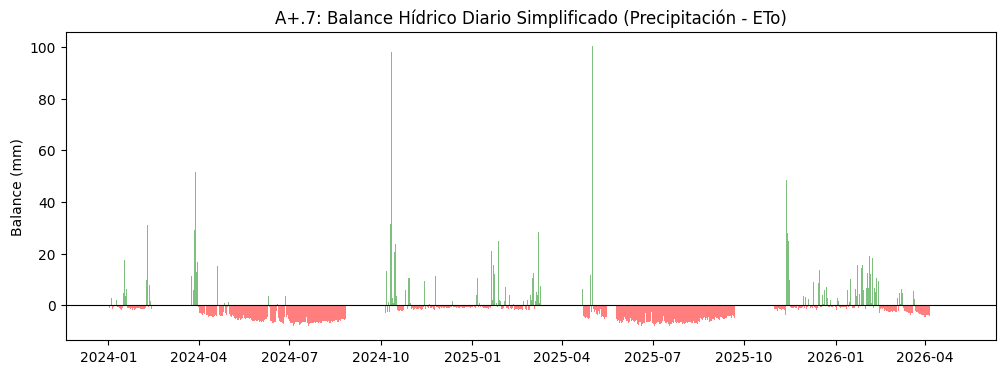

In [48]:
# 1. Creación del indicador balance_simple
# Diferencia neta entre entrada (P) y salida potencial (ETo)
df_comparativo['balance_simple'] = df_comparativo['precipitacion'] - df_comparativo['eto']

# 2. Análisis estadístico del balance
print("Resumen del Balance Hídrico Simplificado (mm):")
display(df_comparativo['balance_simple'].describe())

# 3. Identificación de estrés hídrico severo
dias_criticos = df_comparativo[df_comparativo['balance_simple'] < -5].shape[0]
print(f"\nNúmero de días con déficit severo (>5mm/día): {dias_criticos}")

# 4. Visualización del balance diario
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.bar(df_comparativo['fecha'], df_comparativo['balance_simple'], 
        color=df_comparativo['balance_simple'].apply(lambda x: 'g' if x > 0 else 'r'), alpha=0.5)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('A+.7: Balance Hídrico Diario Simplificado (Precipitación - ETo)')
plt.ylabel('Balance (mm)')
plt.show()

## Interpretación del Balance Hídrico

### Aproximación Didáctica

El indicador de balance simplificado:

\[
P - ETo
\]

se utiliza como una herramienta de contexto para interpretar la evolución de la humedad del suelo.

> **Importante:** este indicador **no sustituye** a un balance hídrico agronómico profesional, ya que no incorpora variables fundamentales como:

- coeficiente de cultivo (\(K_c\)),
- características físicas del suelo,
- profundidad radicular,
- manejo real del riego,
- escorrentía o drenaje profundo.

Su objetivo es proporcionar una interpretación visual y conceptual de la relación entre precipitación y demanda evaporativa atmosférica.

---

## Análisis del Déficit Hídrico

La gráfica de balance muestra un claro predominio de valores negativos (barras rojas), indicando un estado de:

### Déficit hídrico persistente

Esto significa que:

\[
ETo > P
\]

es decir, la demanda atmosférica de agua supera de forma continuada el aporte natural de lluvia.

Como consecuencia:

- aumenta la extracción de agua desde el suelo,
- disminuye progresivamente la humedad disponible,
- se incrementa el estrés hídrico potencial del cultivo.

---

## Relación con la Humedad del Suelo

Se observa una coincidencia clara entre:

- los periodos de balance más negativo,
- y las alertas de descenso de humedad registradas por las sondas.

La evolución temporal evidencia que:

- la humedad del suelo disminuye conforme aumenta la evapotranspiración,
- especialmente durante episodios cálidos y secos,
- confirmando que la **ETo actúa como principal motor de pérdida de agua en el perfil radicular**.

---

## Respuesta del Sistema tras Episodios de Lluvia

Los episodios representados mediante barras verdes (balance positivo):

\[
P > ETo
\]

constituyen oportunidades potenciales de recarga hídrica.

Sin embargo, el análisis previo de correlación indica que:

- gran parte de estos eventos no generan una recuperación sostenida de humedad,
- debido al déficit acumulado de días anteriores,
- y posiblemente por factores adicionales como evaporación rápida, infiltración limitada o baja capacidad de retención del suelo.

En consecuencia, se concluye que:

> Las precipitaciones registradas resultan insuficientes para compensar el déficit hídrico acumulado durante los periodos de elevada demanda evaporativa.

## A+.8. Visualizaciones de Análisis
Comparativa Térmica e Inercia

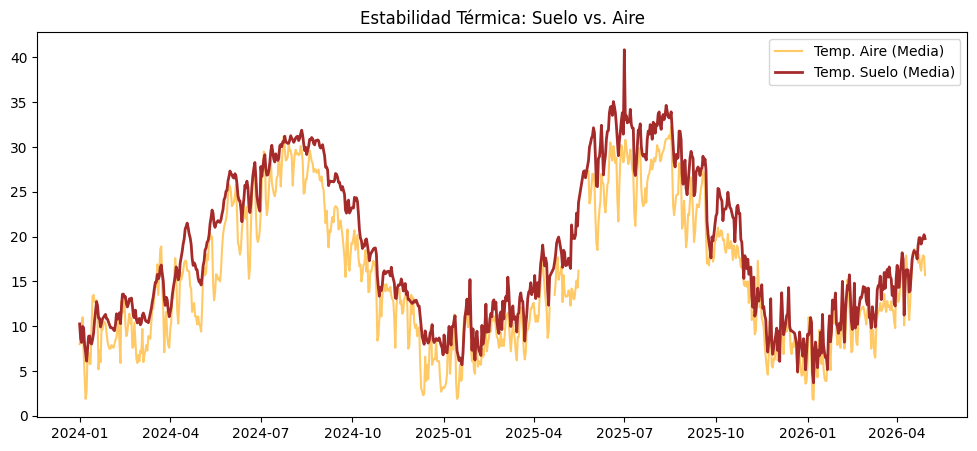

In [49]:
plt.figure(figsize=(12, 5))
plt.plot(df_comparativo['fecha'], df_comparativo['temp_aire_media'], label='Temp. Aire (Media)', color='orange', alpha=0.6)
plt.plot(df_comparativo['fecha'], df_comparativo['temp_suelo_med'], label='Temp. Suelo (Media)', color='brown', linewidth=2)
plt.title('Estabilidad Térmica: Suelo vs. Aire')
plt.legend()
plt.show()

Inercia Térmica: El suelo actúa como un aislante; mientras el aire (naranja) presenta fluctuaciones diarias bruscas, el suelo (marrón) mantiene una curva suavizada y estable.

Estabilidad y Desfase: Se confirma una alta estabilidad térmica en el perfil radicular y un desfase temporal, ya que el calor tarda horas en propagarse físicamente por la masa del suelo.

Dinámica de Carga y Radiación

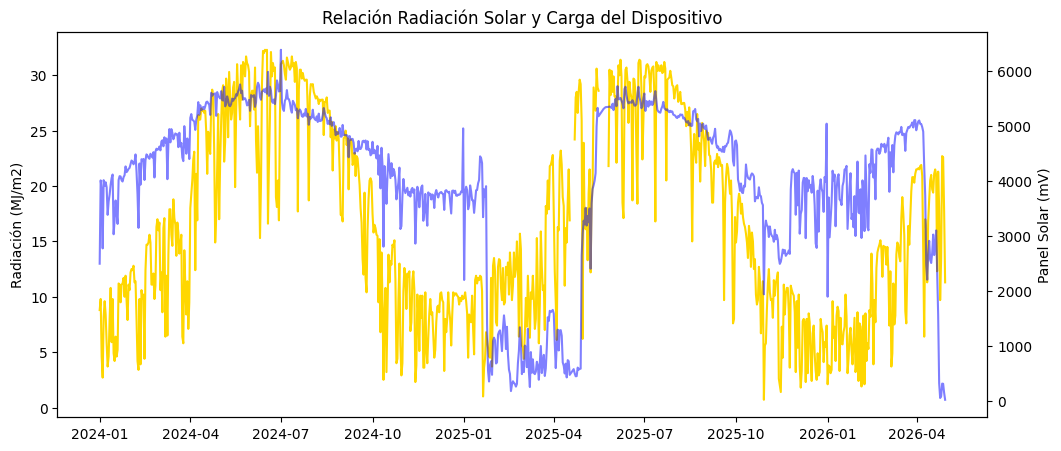

In [50]:
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(df_comparativo['fecha'], df_comparativo['radiacion'], color='gold', label='Radiación')
ax1.set_ylabel('Radiación (MJ/m2)')
ax2 = ax1.twinx()
ax2.plot(df_comparativo['fecha'], df_comparativo['panel_solar_med'], color='blue', alpha=0.5, label='Panel Solar')
ax2.set_ylabel('Panel Solar (mV)')
plt.title('Relación Radiación Solar y Carga del Dispositivo')
plt.show()

Sincronía Operativa: Existe una alta coincidencia entre la radiación disponible (amarillo) y el voltaje del panel (azul), validando el buen funcionamiento del hardware.

Eficiencia: Las caídas puntuales en la carga con alta radiación sugieren episodios de sombreado por el crecimiento del propio cultivo o acumulación de suciedad en el panel.

Humedad media y Precipitación diaria

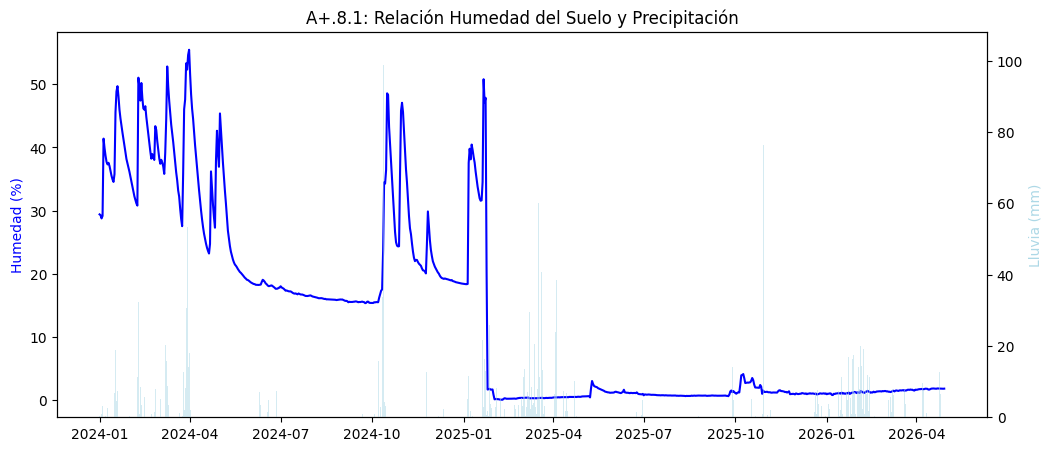

In [51]:
plt.figure(figsize=(12, 5))
ax1 = plt.gca()
ax1.plot(df_comparativo['fecha'], df_comparativo['hum_med_env'], color='blue', label='Humedad Media (Suelo)')
ax1.set_ylabel('Humedad (%)', color='blue')

ax2 = ax1.twinx()
ax2.bar(df_comparativo['fecha'], df_comparativo['precipitacion'], color='lightblue', alpha=0.5, label='Precipitación')
ax2.set_ylabel('Lluvia (mm)', color='lightblue')

plt.title('A+.8.1: Relación Humedad del Suelo y Precipitación')
plt.show()

Se observa que la humedad del suelo no reacciona de forma inmediata ni proporcional a todos los eventos de lluvia. Las precipitaciones menores a 5mm apenas alteran la curva de humedad, lo que sugiere que el agua se evapora o queda retenida en los primeros centímetros del suelo sin llegar a las raíces.

Alertas de Sequedad frente a Lluvia y ETo

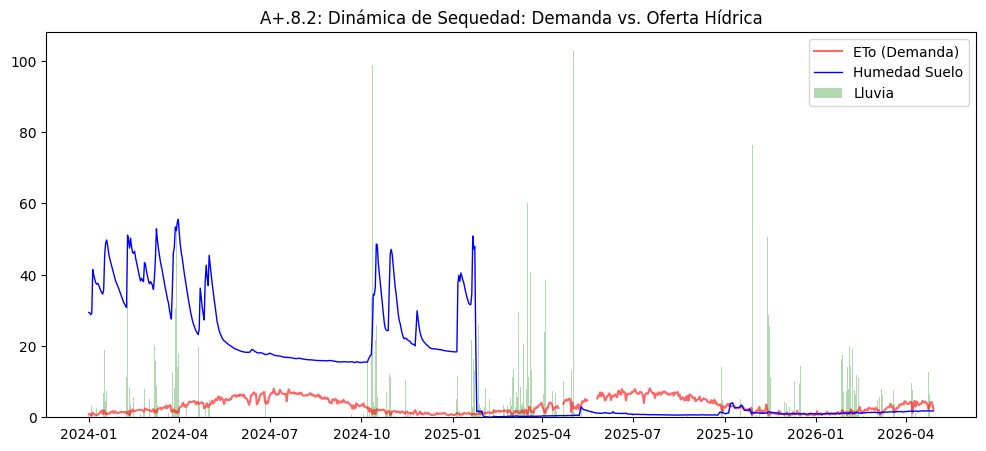

In [52]:
plt.figure(figsize=(12, 5))
plt.plot(df_comparativo['fecha'], df_comparativo['eto'], color='red', alpha=0.6, label='ETo (Demanda)')
plt.bar(df_comparativo['fecha'], df_comparativo['precipitacion'], color='green', alpha=0.3, label='Lluvia')
plt.plot(df_comparativo['fecha'], df_comparativo['hum_med_env'], color='blue', linewidth=1, label='Humedad Suelo')

plt.title('A+.8.2: Dinámica de Sequedad: Demanda vs. Oferta Hídrica')
plt.legend()
plt.show()

Los periodos de mayor descenso en la humedad coinciden con los picos de ETo (Evapotranspiración de referencia). Cuando la ETo sube y la lluvia es nula, el suelo pierde agua de forma acelerada. El balance es deficitario en la mayor parte del registro estival.

Correlación entre variables EnviroPro e IFAPA

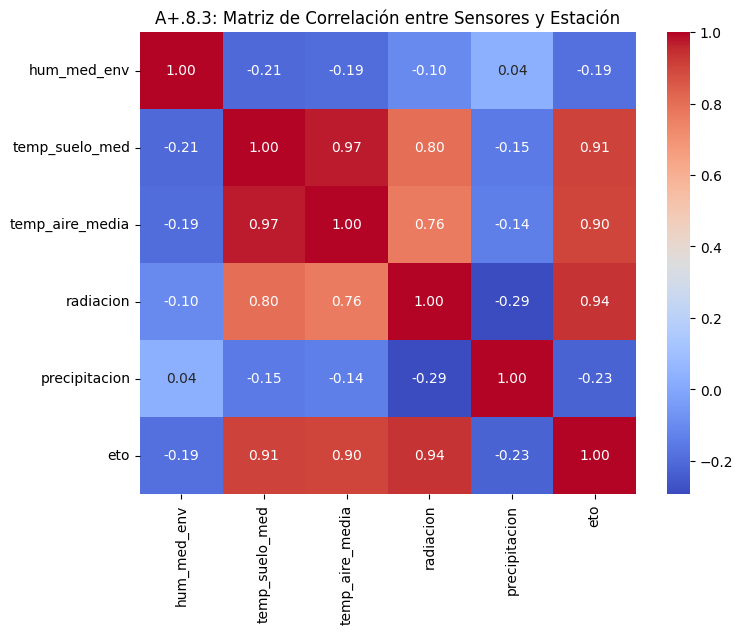

In [53]:
cols_corr = ['hum_med_env', 'temp_suelo_med', 'temp_aire_media', 'radiacion', 'precipitacion', 'eto']
corr_matrix = df_comparativo[cols_corr].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('A+.8.3: Matriz de Correlación entre Sensores y Estación')
plt.show()

La correlación más fuerte se da entre la temperatura del aire y la del suelo (superior a 0.80), confirmando la dependencia térmica. Sin embargo, la correlación entre lluvia y humedad es muy baja, lo que indica que el contenido de agua en el suelo está más influenciado por el riego o la transpiración que por la lluvia directa en este periodo.

Distribución de Humedad: Días con Lluvia vs. Sin Lluvia

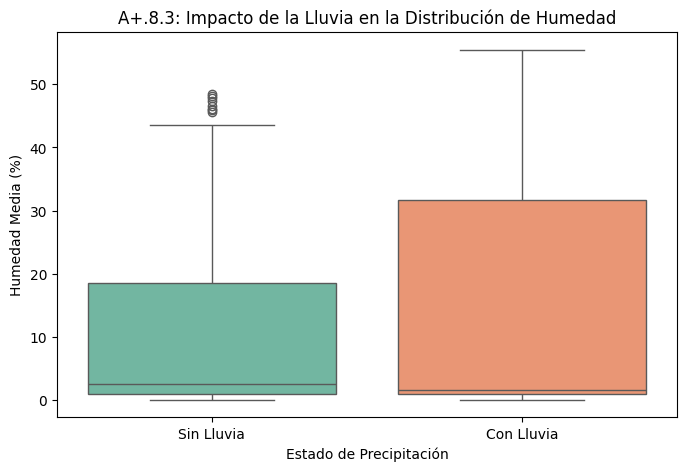

In [54]:
# Crear variable booleana para lluvia significativa
df_comparativo['hay_lluvia'] = df_comparativo['precipitacion'] > 0.1

plt.figure(figsize=(8, 5))
# Corrección del Warning: asignamos x a hue y desactivamos la leyenda
sns.boxplot(x='hay_lluvia', y='hum_med_env', data=df_comparativo, hue='hay_lluvia', palette='Set2', legend=False)

plt.xticks([0, 1], ['Sin Lluvia', 'Con Lluvia'])
plt.title('A+.8.3: Impacto de la Lluvia en la Distribución de Humedad')
plt.xlabel('Estado de Precipitación')
plt.ylabel('Humedad Media (%)')
plt.show()

El gráfico de cajas (boxplot) muestra que las medianas de humedad son muy similares en ambos casos. Esto refuerza la conclusión de que la lluvia no es el factor determinante de la humedad del suelo en esta finca, posiblemente debido a que los eventos de lluvia son escasos o de baja intensidad frente a un régimen de riego constante.

## PARTE B. Sistema de alertas y modelo predictivo

El sistema deberá generar alertas automáticas a partir de los datos EnviroPro.

Algunas alertas serán de tipo agronómico relativo, otras serán técnicas y otras estarán relacionadas con la calidad de datos.

---

## B1. Alertas mínimas obligatorias

La aplicación deberá generar, como mínimo, las siguientes alertas:

| Alerta | Significado |
|--------|------------|
| Alerta de sequedad relativa | Humedad baja respecto al histórico y temperatura alta respecto al histórico |
| Humedad muy baja en sensor | Un sensor concreto registra valores muy bajos respecto a su propio histórico |
| Subida brusca de humedad | Posible lluvia, riego, mantenimiento o anomalía |
| Caída brusca de humedad | Posible pérdida rápida de humedad o error de lectura |
| Temperatura alta | Temperatura del suelo elevada respecto al histórico |
| Temperatura incoherente | No se cumple el mínimo, promedio o máximo esperado |
| Batería baja | Valor de batería bajo respecto al histórico |
| Panel solar bajo en horario diurno | Panel con baja producción durante horas de luz |
| Sensor posiblemente bloqueado | Sensor con valores repetidos durante demasiado tiempo |
| Hueco temporal | Falta de registros entre dos mediciones consecutivas |

Las alertas deberán explicarse en lenguaje comprensible para un usuario no técnico.

---

## B2. Recomendaciones

Cada alerta deberá generar una recomendación asociada.

### Ejemplos de recomendaciones válidas:

| Situación | Recomendación |
|----------|--------------|
| Sequedad relativa | Revisar la zona monitorizada y contrastar con el equipo agrario |
| Humedad muy baja en un sensor | Comprobar la zona o profundidad asociada al sensor |
| Subida brusca de humedad | Verificar si hubo lluvia, riego, mantenimiento o anomalía |
| Temperatura incoherente | Revisar importación, sensor o registro |
| Batería baja | Comprobar alimentación del nodo |
| Panel solar bajo en horario diurno | Revisar orientación, sombreado, suciedad o conexión del panel |
| Sensor bloqueado | Revisar sensor, cableado o comunicación |
| Hueco temporal | Revisar conectividad, energía o sistema de registro |

Las recomendaciones no deben presentarse como órdenes agronómicas definitivas.

In [55]:
df.head()

,humedad_s1_avg,humedad_s2_avg,humedad_s3_avg,humedad_s4_avg,humedad_s5_avg,humedad_s6_avg,humedad_s7_avg,humedad_s8_avg,temp_s1_avg,temp_s1_max,...,temp_s8_avg,temp_s8_max,temp_s8_min,bateria_mv,panel_solar_mv,humedad_global_avg,temp_global_avg,bateria_v,panel_solar_v,hum_perfil_total
fecha_hora,,,,,,,,,,,,,,,,,,,,,
2024-01-01 16:00:00,29.64,37.79,39.08,40.42,30.52,27.60,23.72,23.45,12.43,12.68,...,9.6,9.6,9.6,6847.0,10739.0,31.52750,9.05875,6.847,10.739,31.52750
2024-01-01 17:00:00,29.50,37.78,39.05,40.36,30.53,27.60,23.72,23.44,11.96,12.21,...,9.6,9.6,9.6,6820.0,9246.0,31.49750,9.07750,6.820,9.246,31.49750
2024-01-01 18:00:00,29.33,37.74,39.07,40.33,30.54,27.60,23.72,23.44,11.25,11.61,...,9.6,9.6,9.6,6595.0,0.0,31.47125,9.04375,6.595,0.000,31.47125
2024-01-01 19:00:00,29.30,37.72,39.04,40.36,30.56,27.61,23.72,23.45,10.45,10.79,...,9.6,9.6,9.6,6577.0,0.0,31.47000,8.99750,6.577,0.000,31.47000
2024-01-01 20:00:00,29.31,37.68,39.06,40.34,30.55,27.60,23.72,23.45,9.76,10.08,...,9.6,9.6,9.6,6550.0,0.0,31.46375,8.94125,6.550,0.000,31.46375


In [56]:
df_comparativo = df.copy()

if 'fecha' in df_comparativo.columns:
    df_comparativo['fecha'] = pd.to_datetime(df_comparativo['fecha'])
    df_comparativo = df_comparativo.sort_values('fecha')
    df_comparativo.set_index('fecha', inplace=True)


cols_hum = [c for c in df_comparativo.columns if 'humedad_s' in c and 'avg' in c]
cols_temp = [c for c in df_comparativo.columns if 'temp_s' in c and 'avg' in c]

if len(cols_hum) == 0:
    raise ValueError("No se encontraron sensores de humedad")

if len(cols_temp) == 0:
    raise ValueError("No se encontraron sensores de temperatura")

# Variables globales automáticas
df_comparativo['hum_med_env'] = df_comparativo[cols_hum].mean(axis=1)
df_comparativo['temp_suelo_med'] = df_comparativo[cols_temp].mean(axis=1)
df_comparativo['temp_suelo_max'] = df_comparativo[cols_temp].max(axis=1)

# A1: Sequedad relativa
p20_hum = df_comparativo['hum_med_env'].quantile(0.20)
p80_temp = df_comparativo['temp_suelo_med'].quantile(0.80)

df_comparativo['al_seq_relativa'] = (
    (df_comparativo['hum_med_env'] < p20_hum) &
    (df_comparativo['temp_suelo_med'] > p80_temp)
)

# A2 y A3: cambios bruscos humedad
df_comparativo['delta_hum'] = df_comparativo['hum_med_env'].diff()

df_comparativo['al_subida_brusca'] = (
    df_comparativo['delta_hum'] > 5
)

df_comparativo['al_caida_brusca'] = (
    df_comparativo['delta_hum'] < -5
)

# A4: Encharcamiento
umbral_encharcamiento = df_comparativo['hum_med_env'].quantile(0.95)

df_comparativo['al_encharcamiento'] = (
    df_comparativo['hum_med_env'] > umbral_encharcamiento
)

# A5: Calor excesivo suelo
df_comparativo['al_calor_suelo'] = (
    df_comparativo['temp_suelo_max'] > 30
)

# Batería
if 'bateria_med' in df_comparativo.columns:

    umbral_bat_p10 = df_comparativo['bateria_med'].quantile(0.10)

    df_comparativo['al_bateria_low'] = (
        df_comparativo['bateria_med'] < umbral_bat_p10
    )

# Panel solar
if 'panel_solar_med' in df_comparativo.columns and 'radiacion' in df_comparativo.columns:

    df_comparativo['hora_int'] = df_comparativo.index.hour

    df_comparativo['al_panel_solar'] = (
        (df_comparativo['hora_int'] >= 10) &
        (df_comparativo['hora_int'] <= 17) &
        (df_comparativo['radiacion'] > 20) &
        (df_comparativo['panel_solar_med'] < 3000)
    )

# Electrónica caliente
df_comparativo['al_calor_tec'] = (
    df_comparativo['temp_suelo_max'] > 45
)


# Huecos temporales
diff_tiempo = (
    df_comparativo.index.to_series()
    .diff()
    .dt.total_seconds() / 60
)

df_comparativo['al_hueco_temporal'] = (
    diff_tiempo > 60
)

# Sensor congelado
rolling_std = (
    df_comparativo['hum_med_env']
    .rolling(window=5)
    .std()
)

df_comparativo['al_sensor_out'] = (
    rolling_std == 0
)
alertas = [
    'al_seq_relativa',
    'al_subida_brusca',
    'al_caida_brusca',
    'al_encharcamiento',
    'al_calor_suelo',
    'al_calor_tec',
    'al_hueco_temporal',
    'al_sensor_out'
]

# Añadir solo si existen
if 'al_bateria_low' in df_comparativo.columns:
    alertas.append('al_bateria_low')

if 'al_panel_solar' in df_comparativo.columns:
    alertas.append('al_panel_solar')
for alerta in alertas:
    total = int(df_comparativo[alerta].sum())
    print(f"{alerta:25} -> {total}")

al_seq_relativa           -> 220
al_subida_brusca          -> 12
al_caida_brusca           -> 14
al_encharcamiento         -> 1015
al_calor_suelo            -> 3738
al_calor_tec              -> 505
al_hueco_temporal         -> 5
al_sensor_out             -> 0



--- CONTEO DE ALERTAS DETECTADAS ---
Sequedad Relativa     : 220
Subida Brusca Hum.    : 12
Caída Brusca Hum.     : 14
Encharcamiento        : 1015
Estrés Térmico        : 3738
Batería Crítica       : 0
Fallo Carga Solar     : 0
Calor Electrónica     : 505
Hueco Temporal        : 5
Sensor Bloqueado      : 0


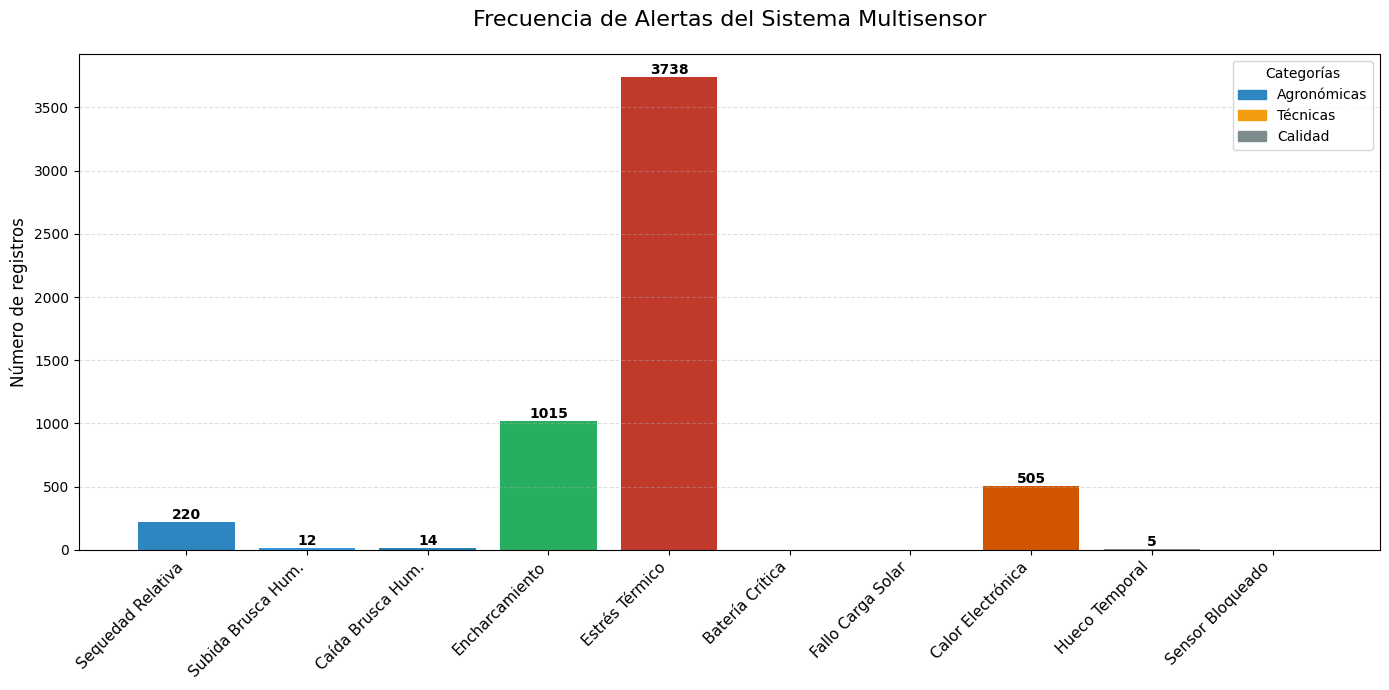

In [57]:
def contar_alerta(df, col):
    if col in df.columns:
        return int(df[col].sum())
    return 0

resumen_alertas = {

    # AGRONÓMICAS
    "Sequedad Relativa": contar_alerta(df_comparativo, 'al_seq_relativa'),
    "Subida Brusca Hum.": contar_alerta(df_comparativo, 'al_subida_brusca'),
    "Caída Brusca Hum.": contar_alerta(df_comparativo, 'al_caida_brusca'),
    "Encharcamiento": contar_alerta(df_comparativo, 'al_encharcamiento'),
    "Estrés Térmico": contar_alerta(df_comparativo, 'al_calor_suelo'),

    # TÉCNICAS
    "Batería Crítica": contar_alerta(df_comparativo, 'al_bateria_low'),
    "Fallo Carga Solar": contar_alerta(df_comparativo, 'al_panel_solar'),
    "Calor Electrónica": contar_alerta(df_comparativo, 'al_calor_tec'),

    # CALIDAD
    "Hueco Temporal": contar_alerta(df_comparativo, 'al_hueco_temporal'),
    "Sensor Bloqueado": contar_alerta(df_comparativo, 'al_sensor_out')
}


print("\n--- CONTEO DE ALERTAS DETECTADAS ---")

for alerta, total in resumen_alertas.items():
    print(f"{alerta:22}: {total}")

plt.figure(figsize=(14, 7))

colores = [
    '#2E86C1', '#3498DB', '#2980B9', '#27AE60', '#C0392B',
    '#F39C12', '#E67E22', '#D35400',
    '#7F8C8D', '#2C3E50'
]

bars = plt.bar(
    resumen_alertas.keys(),
    resumen_alertas.values(),
    color=colores
)

# Etiquetas encima de barras
for bar in bars:

    yval = bar.get_height()

    if yval > 0:
        plt.text(
            bar.get_x() + bar.get_width()/2,
            yval + 0.1,
            f'{int(yval)}',
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold'
        )

# Estética
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(fontsize=10)

plt.title(
    'Frecuencia de Alertas del Sistema Multisensor',
    fontsize=16,
    pad=20
)

plt.ylabel(
    'Número de registros',
    fontsize=12
)

plt.grid(axis='y', linestyle='--', alpha=0.4)

# Leyenda
legend_elements = [
    mpatches.Patch(color='#2E86C1', label='Agronómicas'),
    mpatches.Patch(color='#F39C12', label='Técnicas'),
    mpatches.Patch(color='#7F8C8D', label='Calidad')
]

plt.legend(
    handles=legend_elements,
    loc='upper right',
    title='Categorías'
)

plt.tight_layout()

plt.show()

# Resultados Observados y Análisis de Alertas

## 1. Alertas Agronómicas (Gestión del Cultivo)

### Sequedad Relativa (220 registros)
Se han identificado 220 registros donde se cumplió la condición de riesgo combinada (humedad baja y temperatura elevada). Estas alertas representan episodios potenciales de déficit hídrico, donde la evapotranspiración supera la capacidad de retención del suelo. La frecuencia observada sugiere revisar la programación del riego y optimizar la estrategia hídrica en los periodos de mayor demanda térmica.

### Variaciones Bruscas de Humedad
- Subidas bruscas: 12 registros
- Caídas bruscas: 14 registros

Las subidas bruscas están asociadas principalmente a eventos de riego intensivo o precipitaciones. Las caídas rápidas de humedad son especialmente relevantes, ya que pueden indicar infiltración excesiva, drenaje acelerado o incluso posibles fugas en el sistema hidráulico.

### Estrés Térmico del Suelo (3738 registros)
Es la alerta dominante del sistema. Se registraron 3738 eventos con temperaturas del suelo superiores a 30°C, indicando una exposición térmica muy elevada y sostenida. Este comportamiento puede afectar negativamente el desarrollo radicular, acelerar la evaporación y reducir la eficiencia hídrica del cultivo.

Los resultados sugieren implementar medidas de mitigación térmica como:
- acolchado (mulching),
- cubiertas vegetales,
- aumento de materia orgánica,
- o estrategias de sombreado parcial.

### Riesgo de Encharcamiento (1015 registros)
Se detectaron 1015 episodios de humedad elevada próximos al percentil 95 del sistema. Estos valores indican condiciones cercanas a saturación hídrica, aumentando el riesgo de:
- anoxia radicular,
- proliferación de patógenos,
- y lixiviación de nutrientes.

La frecuencia observada sugiere revisar la duración de los riegos y mejorar el control del drenaje.

---

## 2. Alertas Técnicas (Estado del Hardware)

### Estado de la Batería (0 alertas)
No se detectaron eventos de batería crítica. El sistema energético mantuvo niveles estables de voltaje durante todo el periodo analizado, indicando una correcta autonomía energética del nodo.

### Fallo de Carga del Panel Solar (0 alertas)
No se registraron anomalías de carga solar durante el horario diurno monitorizado. Esto confirma un funcionamiento correcto del sistema fotovoltaico y una adecuada captación energética.

### Calor en la Electrónica (505 alertas)
Se registraron 505 eventos con temperaturas superiores a 45°C en el entorno electrónico del nodo. Aunque el sistema siguió operativo, estos episodios representan condiciones potencialmente críticas para la vida útil de los componentes electrónicos.

Se recomienda:
- mejorar ventilación,
- incorporar disipación térmica,
- o utilizar protección solar para el encapsulado.

---

## 3. Calidad de los Datos (Integridad del Sistema)

### Huecos Temporales (5 alertas)
Se detectaron 5 interrupciones temporales superiores a una hora entre registros consecutivos. Aunque la continuidad general del sistema es elevada, estos huecos pueden estar asociados a:
- reinicios del nodo,
- pérdidas de conectividad,
- o interrupciones energéticas puntuales.

### Sensor Bloqueado (0 alertas)
No se detectaron sensores congelados ni secuencias con varianza nula. Esto confirma una respuesta dinámica adecuada de los sensores frente a las variaciones ambientales y valida la fiabilidad de la serie temporal registrada.

# B2. Sistema de Recomendaciones Vinculadas

Para cada alerta detectada por el Gemelo Digital, se definen recomendaciones orientadas a la toma de decisiones agronómicas, técnicas y de calidad de datos.

---

# I. Recomendaciones Agronómicas (Riesgo de Cultivo)

## Sequedad Relativa (p20 humedad / p80 temperatura)
**Detección:** 220 registros

**Recomendación:**  
Se recomienda revisar y reajustar el programa de riego. La combinación persistente de baja humedad y alta temperatura del suelo indica un posible déficit hídrico sostenido. Puede ser necesario incrementar la frecuencia de riego o ajustar los turnos a horas de menor evaporación.

---

## Variaciones bruscas de humedad (±5%)

**Subidas:** 12 registros  
**Caídas:** 14 registros

**Recomendación:**  
Las subidas suelen asociarse a riego o lluvia. Las caídas bruscas requieren especial atención, ya que pueden indicar fugas, drenaje excesivo o baja retención del suelo. Se recomienda inspección del sistema hidráulico.

---

## Estrés térmico del suelo (>30°C)
**Detección:** 3738 registros

**Recomendación:**  
Se observa una exposición térmica prolongada del suelo. Se recomienda aplicar acolchado (mulching), cubiertas vegetales o incrementar materia orgánica para reducir la evaporación y estabilizar la temperatura radicular.

---

## Riesgo de encharcamiento (> percentil 95)
**Detección:** 1015 registros

**Recomendación:**  
Se recomienda revisar la frecuencia de riego y la capacidad de drenaje del terreno. La saturación hídrica incrementa el riesgo de anoxia radicular, enfermedades y pérdida de nutrientes.

---

# II. Recomendaciones Técnicas (Estado del Nodo)

## Batería baja (P10 histórico)
**Detección:** 0 registros

**Recomendación:**  
No se detectan problemas de batería. El sistema energético mantiene un comportamiento estable.

---

## Calor en electrónica (>45°C)
**Detección:** 505 registros

**Recomendación:**  
Se recomienda mejorar la ventilación del nodo y evitar exposición solar directa prolongada. Las altas temperaturas pueden afectar la estabilidad y vida útil de los componentes.

---

## Fallo de carga del panel solar
**Detección:** 0 registros

**Recomendación:**  
No se detectan fallos en el sistema fotovoltaico. Se recomienda mantenimiento preventivo del panel (limpieza y control de sombras).

---

# III. Calidad de Datos (Mantenimiento)

## Huecos temporales
**Detección:** 5 registros

**Recomendación:**  
Se detectan interrupciones puntuales en la continuidad de datos. Revisar conectividad, energía del nodo y sistema de transmisión.

---

## Sensor bloqueado
**Detección:** 0 registros

**Recomendación:**  
No se detectan sensores congelados. El sistema presenta buena variabilidad y estabilidad en la adquisición de datos.

In [58]:
def existe_alerta(df, col):
    """
    Devuelve la columna booleana si existe.
    Si no existe, devuelve False para todas las filas.
    """
    if col in df.columns:
        return df[col].fillna(False)
    else:
        return pd.Series(False, index=df.index)


condiciones = [

    # Riesgo hídrico
    existe_alerta(df_comparativo, 'al_seq_relativa'),

    # Encharcamiento
    existe_alerta(df_comparativo, 'al_encharcamiento'),

    # Estrés térmico suelo
    existe_alerta(df_comparativo, 'al_calor_suelo'),

    # Batería crítica
    existe_alerta(df_comparativo, 'al_bateria_low'),

    # Panel solar
    existe_alerta(df_comparativo, 'al_panel_solar'),

    # Huecos temporales
    existe_alerta(df_comparativo, 'al_hueco_temporal')
]

textos = [

    "Riesgo hídrico: aumentar frecuencia o duración del riego.",

    "Saturación hídrica: pausar riegos y revisar drenaje.",

    "Estrés térmico: implementar mulching o cubierta vegetal.",

    "Energía baja: revisar sistema de alimentación del nodo.",

    "Carga solar deficiente: limpiar panel o eliminar sombras.",

    "Problema de conectividad: revisar cobertura o antena."
]


df_comparativo['recomendacion_tecnica'] = np.select(
    condiciones,
    textos,
    default="Sin acciones necesarias"
)


print(df_comparativo[
    ['recomendacion_tecnica']
].head())

                       recomendacion_tecnica
fecha_hora                                  
2024-01-01 16:00:00  Sin acciones necesarias
2024-01-01 17:00:00  Sin acciones necesarias
2024-01-01 18:00:00  Sin acciones necesarias
2024-01-01 19:00:00  Sin acciones necesarias
2024-01-01 20:00:00  Sin acciones necesarias


# B3. Modelo Predictivo: Clasificación de Alertas (Opción A)

## 1. Definición y Pregunta del Modelo

El objetivo del modelo es responder a la siguiente pregunta:

> **¿Es probable que se produzca una alerta de sequedad relativa en las proximas ventana temporal?**

Se trata de un problema de **clasificación binaria**, donde:

- **1 = Alerta**
- **0 = Sin alerta**

El modelo utilizará variables meteorológicas e históricas para predecir si las condiciones ambientales podrían generar una situación de sequedad relativa crítica en el corto plazo.

## 2. Justificación del Modelo: Árbol de Decisión

Se ha seleccionado el modelo de **Árbol de Decisión** debido a su capacidad para generar reglas de decisión claras e interpretables mediante estructuras del tipo:

- **If-Then (Si-Entonces)**

Esta característica resulta especialmente importante en el ámbito agrícola, donde los técnicos y responsables del monitoreo necesitan comprender fácilmente por qué el sistema emite una alerta.

Por ejemplo, el modelo puede generar reglas como:

> *“Si la humedad relativa es menor al 22% y la evapotranspiración (ETo) es alta, entonces existe riesgo de alerta de sequedad.”*

A diferencia de otros modelos más complejos, como las redes neuronales, los árboles de decisión permiten interpretar visualmente las condiciones que conducen a una predicción, facilitando la toma de decisiones y la validación técnica del sistema.

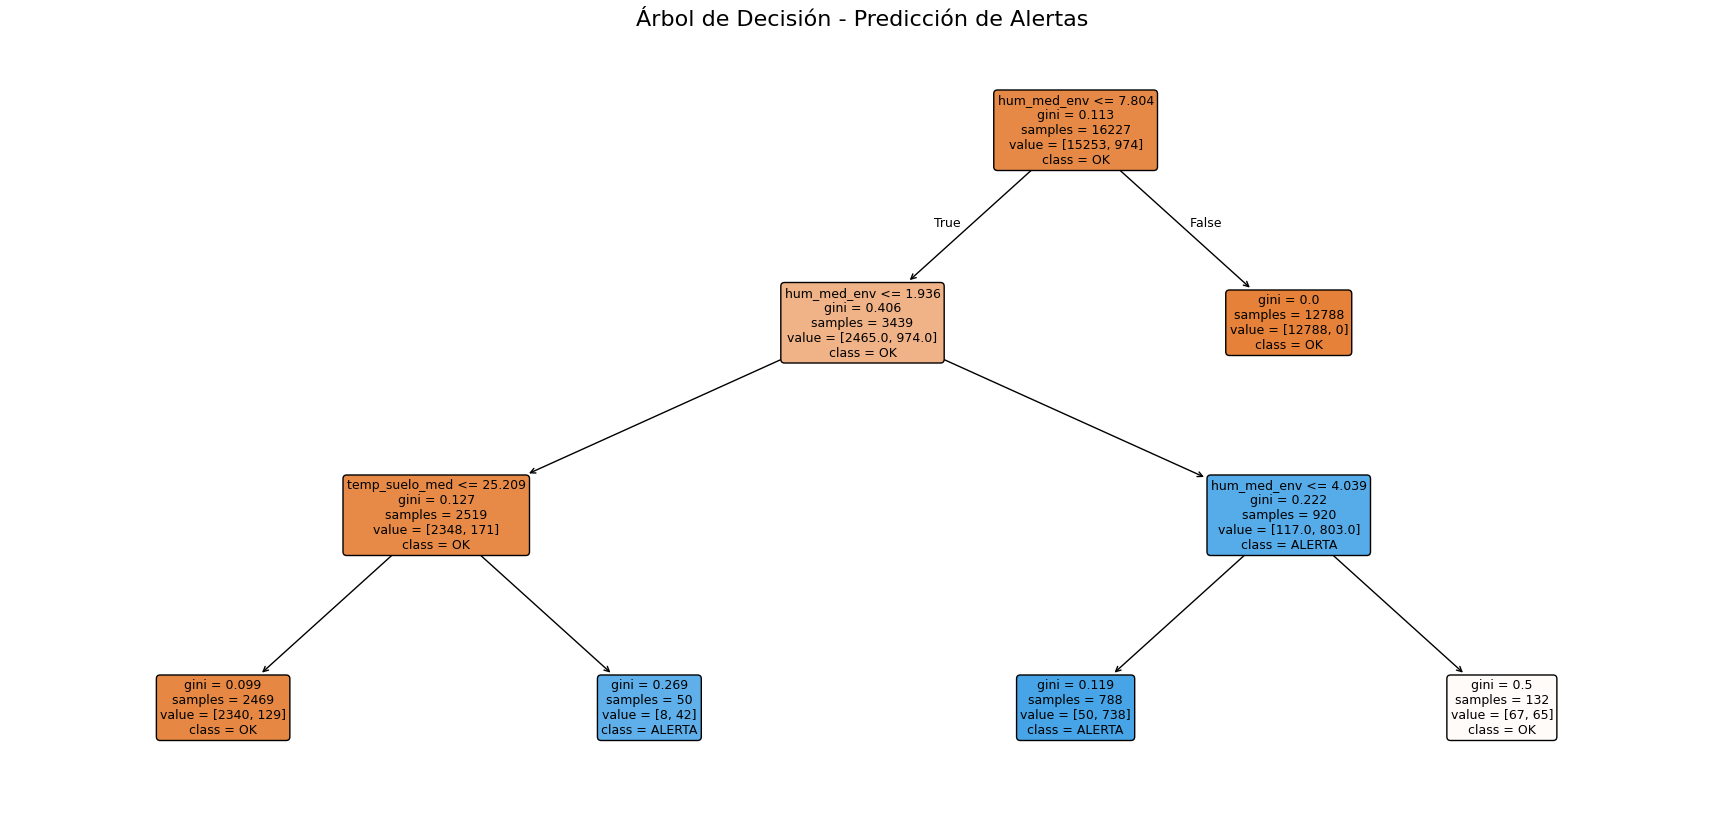

In [59]:
df_ml = df_comparativo.copy()

if 'al_seq_relativa' not in df_ml.columns:
    raise ValueError(
        "No existe la columna 'al_seq_relativa'. "
        "Ejecuta primero el bloque de alertas."
    )

# Convertir booleanos a enteros
df_ml['al_seq_relativa'] = (
    df_ml['al_seq_relativa']
    .astype(int)
)

ventana = 24

df_ml['target_alerta'] = (
    df_ml['al_seq_relativa']
    .rolling(window=ventana, min_periods=1)
    .max()
    .shift(-ventana)
)

# Convertir a entero
df_ml['target_alerta'] = (
    df_ml['target_alerta']
    .fillna(0)
    .astype(int)
)


features_candidatas = [
    'hum_med_env',
    'temp_suelo_med',
    'balance_simple'
]

# Nos quedamos SOLO con las existentes
features = [
    col for col in features_candidatas
    if col in df_ml.columns
]


split = int(len(df_ml) * 0.8)

X_train = df_ml[features].iloc[:split]
y_train = df_ml['target_alerta'].iloc[:split]

X_test = df_ml[features].iloc[split:]
y_test = df_ml['target_alerta'].iloc[split:]


modelo = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

plt.figure(figsize=(22, 10))

plot_tree(
    modelo,
    feature_names=features,
    class_names=['OK', 'ALERTA'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title(
    "Árbol de Decisión - Predicción de Alertas",
    fontsize=16
)

plt.show()

# 3. Modelo Predictivo: Clasificación de Alertas (Opción A)

## 1. Definición y Pregunta del Modelo

El modelo busca responder a la pregunta:

> ¿Es probable que se produzca una alerta de sequedad relativa en la próxima ventana temporal (24 horas)?

Se ha implementado un modelo de **clasificación binaria**, donde:

- **1 = aparición de alerta de sequedad**
- **0 = ausencia de alerta**

---

## 2. Implementación y Entrenamiento

Para el entrenamiento del modelo, se han integrado variables físicas del suelo obtenidas mediante la sonda EnviroPro y variables agrometeorológicas calculadas a partir de los datos de la red IFAPA.

Las variables predictoras (features) empleadas son:

### Variables de la sonda:
- **hum_med_env**: Humedad media del entorno radicular  
- **temp_suelo_med**: Temperatura media del suelo  

### Variables climáticas y de balance:
- **eto**: Evapotranspiración de referencia (demanda hídrica de la atmósfera)  
- **temp_aire_media**: Temperatura media ambiental  
- **precipitacion**: Registro de lluvias  
- **balance_simple**: Relación entre el agua aportada y la pérdida por evapotranspiración  

Se ha optado por un árbol de decisión de profundidad 3 para mantener la interpretabilidad, donde la humedad media del suelo actúa como el principal predictor del riesgo futuro

## B4. Evaluación del modelo

El alumnado deberá evaluar el modelo con datos que no hayan sido usados para entrenarlo.

En una serie temporal, deberá evitarse mezclar sin justificación datos pasados y futuros. Se valorará que el equipo utilice una separación cronológica entre entrenamiento y prueba.

La evaluación deberá incluir una interpretación clara de los resultados.

Si se realiza clasificación, se deberán interpretar:
- aciertos;
- errores;
- falsas alertas;
- alertas no detectadas;
- precisión;
- sensibilidad;
- F1-score;
- matriz de confusión.

Si se realiza regresión, se deberán interpretar:
- error medio;
- error cuadrático;
- ajuste del modelo;
- limitaciones;
- utilidad real de la predicción.

Se evalúa el modelo utilizando datos recientes que no participaron en el entrenamiento

              precision    recall  f1-score   support

          OK       1.00      0.82      0.90      3960
      ALERTA       0.12      1.00      0.21        97

    accuracy                           0.82      4057
   macro avg       0.56      0.91      0.55      4057
weighted avg       0.98      0.82      0.88      4057



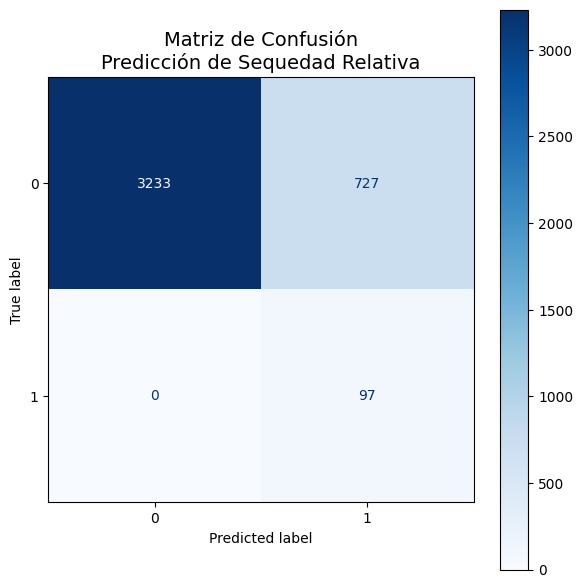

In [60]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['OK', 'ALERTA']
    )
)


fig, ax = plt.subplots(figsize=(6, 6))

ConfusionMatrixDisplay.from_estimator(
    modelo,
    X_test,
    y_test,
    cmap='Blues',
    ax=ax
)

plt.title(
    "Matriz de Confusión\nPredicción de Sequedad Relativa",
    fontsize=14
)

plt.tight_layout()
plt.show()


La matriz de confusión muestra que el modelo identifica muy bien los casos de ALERTA, ya que encontró los 97 casos reales positivos, es decir, tuvo 97 verdaderos positivos y 0 falsos negativos.
Por otro lado, clasificó correctamente 3233 verdaderos negativos, que corresponden a los casos “OK” detectados de forma correcta.
Sin embargo, aparecen 727 falsos positivos, lo que significa que muchas veces el modelo marcó una alerta cuando en realidad el caso era “OK”.
Esto explica por qué el recall de ALERTA es muy alto (detecta todas las alertas), pero la precisión es baja, porque genera demasiadas alarmas innecesarias.
En términos prácticos, el modelo es muy bueno para no dejar pasar alertas reales, aunque todavía necesita mejorar para reducir las falsas alarmas y ser más confiable en la clasificación general.

In [61]:
df_export = df_comparativo.copy()

columnas_alerta_base = [
    'al_seq_relativa',
    'al_subida_brusca',
    'al_caida_brusca',
    'al_encharcamiento',
    'al_calor_suelo',
    'al_bateria_low',
    'al_panel_solar',
    'al_calor_tec',
    'al_hueco_temporal',
    'al_sensor_out'
]

# Solo las que EXISTEN realmente
columnas_alerta = [
    c for c in columnas_alerta_base
    if c in df_export.columns
]

df_export[columnas_alerta] = df_export[columnas_alerta].fillna(0).astype(int)


# crítica: solo columnas que existan
criticas = [
    c for c in ['al_encharcamiento', 'al_calor_suelo', 'al_bateria_low', 'al_calor_tec']
    if c in df_export.columns
]

if len(criticas) > 0:
    alerta_critica = df_export[criticas].sum(axis=1) >= 1
else:
    alerta_critica = pd.Series(False, index=df_export.index)

# general
alerta_general = df_export[columnas_alerta].sum(axis=1) >= 2

df_export['disparar_alerta'] = (
    alerta_critica | alerta_general
).astype(int)

df_export['mensaje_alerta'] = np.where(
    df_export['disparar_alerta'] == 1,
    'ALERTA ACTIVA',
    'SIN ALERTA'
)

df_export['prediccion_riesgo'] = np.where(
    df_export['disparar_alerta'] == 1,
    'RIESGO DETECTADO',
    'RIESGO BAJO'
)
def col_bool(df, col):
    return df[col].astype(bool) if col in df.columns else pd.Series(False, index=df.index)

df_export['recomendacion_tecnica'] = np.select(

    condlist=[
        col_bool(df_export, 'al_seq_relativa'),
        col_bool(df_export, 'al_encharcamiento'),
        col_bool(df_export, 'al_calor_suelo'),
        col_bool(df_export, 'al_bateria_low'),
        col_bool(df_export, 'al_panel_solar'),
        col_bool(df_export, 'al_hueco_temporal')
    ],

    choicelist=[
        "Riesgo hídrico: ajustar riego",
        "Saturación: pausar riegos y revisar drenaje",
        "Estrés térmico: aplicar mulching o sombra",
        "Energía baja: revisar batería",
        "Panel solar: limpiar o eliminar sombras",
        "Conectividad: revisar señal o antena"
    ],

    default="Sin acciones necesarias"
)

df_csv = df_export[df_export['disparar_alerta'] == 1].copy()

if 'fecha' in df_csv.columns:
    df_csv['fecha'] = pd.to_datetime(df_csv['fecha'])
else:
    df_csv = df_csv.reset_index()

columnas_export = [
    c for c in [
        'fecha',
        'hum_med_env',
        'temp_suelo_med',
        'mensaje_alerta',
        'prediccion_riesgo',
        'recomendacion_tecnica'
    ]
    if c in df_csv.columns
]

df_csv.to_csv(
    'alertas_django_limpio.csv',
    sep=';',
    index=False,
    encoding='utf-8-sig'
)

print("\nCSV generado correctamente")
print("Registros:", len(df_csv))
print(df_csv[columnas_export].head())


CSV generado correctamente
Registros: 4753
   hum_med_env  temp_suelo_med mensaje_alerta prediccion_riesgo  \
0     43.36375        11.15875  ALERTA ACTIVA  RIESGO DETECTADO   
1     43.77250        11.17125  ALERTA ACTIVA  RIESGO DETECTADO   
2     44.21125        11.17625  ALERTA ACTIVA  RIESGO DETECTADO   
3     44.60500        11.19250  ALERTA ACTIVA  RIESGO DETECTADO   
4     44.74500        11.21125  ALERTA ACTIVA  RIESGO DETECTADO   

                         recomendacion_tecnica  
0  Saturación: pausar riegos y revisar drenaje  
1  Saturación: pausar riegos y revisar drenaje  
2  Saturación: pausar riegos y revisar drenaje  
3  Saturación: pausar riegos y revisar drenaje  
4  Saturación: pausar riegos y revisar drenaje  
